In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import glob
import pickle
import threading
import traceback
from concurrent.futures import ThreadPoolExecutor, as_completed
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.layers import ELU1
from digitalbat.training.trainer import bat_former_trainer, finetune_readout_trainer
from digitalbat.utility.utils import set_random_state, poisson_fde_population, corr


In [2]:
SEED = 1
WD_GRID = [0.01, 0.1]
WD_SCRATCH_GRID = [0.01, 0.1, 1.0]
DEVICE = 'cuda'

# Training budget (see plan: user chose smoke-test sizing)
N_EPOCHS_FOUNDATION = 1000
N_EPOCHS_FINETUNE = 1000
N_EPOCHS_SCRATCH = 1000
EARLY_STOP_PATIENCE = 100
LR = 1e-2

# Parallel-within-GPU training. Tune based on `nvidia-smi` VRAM headroom.
MAX_WORKERS = 32

OUT_ROOT = os.path.abspath('./out/transfer')
os.makedirs(OUT_ROOT, exist_ok=True)

set_random_state(SEED)

# Dataloader (all 18 sessions)

In [3]:
data_config = dict(
    use_speed_head_dir = False,
    use_IMU_flag = False,
    use_click_flag = False,
    use_LFP_flag = False,
    use_ripple_flag = False,
    only_flight_flag = True,
    firing_rate_criterion_flag = True,
    max_acceleration = 50,
    no_3d_location = False,
    spike_count_flag = True,
    bin_width = 0.10,
    split_flights_for_train = 'random',
    type_train_num = 1,
    type_valid_num = 1,
    special_id_count_thresh = 3,
    only_use_special_id_4train_flag = False,
    shuffle_flag = True,
    time_shuffle_for_trajecotry_flag = False,
    simulate_place_cell_flag = False,
    split_each_trajectory_flag = True,
    window_size = None,
    stride_train = None,
    stride_test = None,
    batch_size_train = None,
    batch_size_test = None,
    session_names = [
        'Dataset_3_14543_240419',
        'Dataset_3_14543_240420',
        'Dataset_3_14543_240421',
        'Dataset_3_29959_240402',
        'Dataset_3_29959_240403',
        'Dataset_3_29959_240404',
        'Dataset_2_14445_231208',
        'Dataset_2_14445_231209',
        'Dataset_1_32622_231009',
        'Dataset_1_32622_231010',
        'Dataset_1_32622_231007',
        'Dataset_2_14611_231208',
        'Dataset_2_14611_231209',
        'Dataset_3_00000_240402',
        'Dataset_3_00000_240403',
        'Dataset_3_00000_240404',
        'Dataset_3_00000_240405',
        'Dataset_3_29959_240405',
    ],
    parent_folder = '/mnt/s5/Adam/Angelo/NP_datasets/',
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'Loaded {len(unit_num_dict)} sessions, behavior_dim={behavior_dim}')
print(f'Units per session: {unit_num_dict}')

  Acceleration filter: removed 1/37 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
Loaded 18 sessions, behavior_dim=3
Units per session: {'Dataset_3_14543_240419': 204, 'Dataset_3_14543_240420': 77, 'Dataset_3_14543_240421': 65, 'Dataset_3_29959_240402': 266, 'Dataset_3_29959_240403': 149, 'Dataset_3_29959_240404': 121, 'Dataset_2_14445_231208': 155, 'Dataset_2_14445_231209': 102, 'Dataset_1_32622_231009':

# Experiment bookkeeping

In [4]:
SESSIONS = list(unit_num_dict)

def dataset_of(session_name):
    # 'Dataset_{N}_...' -> 'D{N}'
    return 'D' + session_name.split('_')[1]

def bat_of(session_name):
    # 'Dataset_{N}_{bat_id}_{date}'
    return session_name.split('_')[2]

SESSIONS_D13 = [s for s in SESSIONS if dataset_of(s) != 'D2']
SESSIONS_D2  = [s for s in SESSIONS if dataset_of(s) == 'D2']

BATS = sorted({bat_of(s) for s in SESSIONS})
BATS_D13 = sorted({bat_of(s) for s in SESSIONS_D13})

print(f'All sessions ({len(SESSIONS)}): {SESSIONS}')
print(f'D1+D3 sessions ({len(SESSIONS_D13)}): {SESSIONS_D13}')
print(f'D2 sessions ({len(SESSIONS_D2)}): {SESSIONS_D2}')
print(f'Bats ({len(BATS)}): {BATS}')
print(f'Bats D1+D3 ({len(BATS_D13)}): {BATS_D13}')

All sessions (18): ['Dataset_3_14543_240419', 'Dataset_3_14543_240420', 'Dataset_3_14543_240421', 'Dataset_3_29959_240402', 'Dataset_3_29959_240403', 'Dataset_3_29959_240404', 'Dataset_2_14445_231208', 'Dataset_2_14445_231209', 'Dataset_1_32622_231009', 'Dataset_1_32622_231010', 'Dataset_1_32622_231007', 'Dataset_2_14611_231208', 'Dataset_2_14611_231209', 'Dataset_3_00000_240402', 'Dataset_3_00000_240403', 'Dataset_3_00000_240404', 'Dataset_3_00000_240405', 'Dataset_3_29959_240405']
D1+D3 sessions (14): ['Dataset_3_14543_240419', 'Dataset_3_14543_240420', 'Dataset_3_14543_240421', 'Dataset_3_29959_240402', 'Dataset_3_29959_240403', 'Dataset_3_29959_240404', 'Dataset_1_32622_231009', 'Dataset_1_32622_231010', 'Dataset_1_32622_231007', 'Dataset_3_00000_240402', 'Dataset_3_00000_240403', 'Dataset_3_00000_240404', 'Dataset_3_00000_240405', 'Dataset_3_29959_240405']
D2 sessions (4): ['Dataset_2_14445_231208', 'Dataset_2_14445_231209', 'Dataset_2_14611_231208', 'Dataset_2_14611_231209']
Bats

# Helpers

In [5]:
def filter_dataloaders(dataloaders, keep_sessions):
    """Return a new train/valid/test dict restricted to `keep_sessions` (preserving order)."""
    keep = list(keep_sessions)
    return {
        split: {s: dataloaders[split][s] for s in keep if s in dataloaders[split]}
        for split in ('train', 'valid', 'test')
    }


MODEL_CONFIG_BASE = dict(
    use_place_as_input=False,
    use_trajectory_as_input=True,
    latent_dim=32,
    ff_dim=32,
    num_heads=4,
    num_layers=1,
    dropout_prob=0.3,
    final_activation=ELU1(),
)

def build_bat_former(unit_num_sub, behavior_dim, seed=SEED):
    """Fresh Bat_Transformer with readouts sized for sessions in `unit_num_sub`."""
    set_random_state(seed)
    return Bat_Transformer(
        input_dim=behavior_dim,
        output_dim_dict=unit_num_sub,
        **MODEL_CONFIG_BASE,
    )


def freeze_core_for_finetune(model, target_session):
    """Freeze transformer core and all non-target readouts; keep readouts[target_session] trainable."""
    for p in model.parameters():
        p.requires_grad = False
    for p in model.readouts[target_session].parameters():
        p.requires_grad = True
    # sanity check
    n_train = sum(p.requires_grad for p in model.parameters())
    n_target = sum(p.requires_grad for p in model.readouts[target_session].parameters())
    assert n_train == n_target, f'freeze mismatch: {n_train} != {n_target}'
    return model

In [6]:
def ckpt_path(group, heldout, suffix=''):
    """./out/transfer/{group}/bat_former_seed_{SEED}_wd_sweep_by_{group}_held_{heldout}{suffix}.pth

    The literal `wd_sweep` token replaces the previous fixed-WD value: each model now picks
    its own WD from WD_GRID by validation score. The canonical save_path holds the chosen
    best; per-WD checkpoints from the sweep live alongside at `wd_path(save_path, wd)`.
    """
    d = os.path.join(OUT_ROOT, group)
    os.makedirs(d, exist_ok=True)
    name = f'bat_former_seed_{SEED}_wd_sweep_by_{group}_held_{heldout}{suffix}.pth'
    return os.path.join(d, name)


def wd_path(save_path, wd):
    """Per-WD checkpoint path used during the sweep; the canonical save_path holds the best."""
    base, ext = os.path.splitext(save_path)
    return f'{base}__wd{wd}{ext}'


def eval_on_session(model, session, dataloaders, split='test'):
    """Return per-neuron FDE and mean corr on the given session/split."""
    model = model.to(DEVICE)
    model.eval()
    y_true_list, y_pred_list = [], []
    with torch.no_grad():
        for batch in dataloaders[split][session]:
            X = batch.behavior.to(DEVICE)
            mask = batch.mask.to(DEVICE)
            y = batch.spike.to(DEVICE)
            y_pred = model(session, X, mask)
            y_true_list.append(y.detach()[mask == 1.0].cpu().numpy())
            y_pred_list.append(y_pred.detach()[mask == 1.0].cpu().numpy())
    y_true = np.vstack(y_true_list)
    y_pred = np.vstack(y_pred_list)
    fde = poisson_fde_population(y_true, y_pred)
    pc = corr(y_true, y_pred, axis=0)
    return fde, pc

# Parallel-within-GPU runner

A ThreadPoolExecutor shares one CUDA context; distinct `nn.Module` instances don't race on each other's parameters. We give each worker its own `torch.cuda.Stream` so kernels interleave instead of serializing on the default stream. If VRAM is tight, lower `MAX_WORKERS`: tasks that OOM get retried serially at the end.

In [7]:
def _run_on_stream(fn):
    stream = torch.cuda.Stream()
    with torch.cuda.stream(stream):
        out = fn()
    stream.synchronize()
    return out


def run_tasks_parallel(tasks, max_workers=MAX_WORKERS, label=''):
    """
    tasks: list of (task_id, callable_no_args) tuples.
    Returns: {task_id: result}. OOM failures are retried serially after the parallel wave.
    """
    results = {}
    oom_retries = []

    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        futs = {pool.submit(_run_on_stream, fn): tid for tid, fn in tasks}
        for fut in as_completed(futs):
            tid = futs[fut]
            try:
                results[tid] = fut.result()
                print(f'[{label}] done: {tid}')
            except torch.cuda.OutOfMemoryError:
                print(f'[{label}] OOM on {tid}, will retry serially')
                oom_retries.append(tid)
            except Exception as e:
                print(f'[{label}] {tid} FAILED: {type(e).__name__}: {e}')
                traceback.print_exc()
                results[tid] = None

    if oom_retries:
        torch.cuda.empty_cache()
        tid_to_fn = dict(tasks)
        for tid in oom_retries:
            try:
                print(f'[{label}] serial retry: {tid}')
                results[tid] = tid_to_fn[tid]()
            except Exception as e:
                print(f'[{label}] {tid} FAILED (serial): {e}')
                results[tid] = None
    return results

# Single-fold training primitives

In [8]:
def _sweep_wd_train(build_fn, dl_sub, save_path, n_epochs,
                     target_session=None, wd_grid=WD_GRID):
    """
    For each WD in `wd_grid`, train a fresh model (via `build_fn()`) and save its checkpoint
    to `wd_path(save_path, wd)`. After the sweep, copy the best-by-validation checkpoint to
    the canonical `save_path` and return (best_score, best_model, best_wd).

    `target_session` is None for foundation/scratch (uses bat_former_trainer) and set for
    finetune (uses finetune_readout_trainer).
    """
    finetune = target_session is not None
    sweep_results = []  # (score, wd, sweep_path)
    for wd in wd_grid:
        sweep_save = wd_path(save_path, wd)
        model = build_fn()
        cfg = dict(
            model=model, dataloaders=dl_sub, device=DEVICE,
            n_epochs=n_epochs, lr=LR, weight_decay=wd,
            loss_fn=nn.PoissonNLLLoss(log_input=False),
            valid_fn=poisson_fde_population, valid_stat='median',
            early_stopping_patience=EARLY_STOP_PATIENCE,
            save_model=True, model_name=sweep_save,
        )
        if finetune:
            cfg['target_session'] = target_session
            score, _, _ = finetune_readout_trainer(**cfg)
        else:
            score, _, _ = bat_former_trainer(**cfg)
        sweep_results.append((float(score), wd, sweep_save))
        del model
        torch.cuda.empty_cache()

    best_score, best_wd, best_sweep_path = max(sweep_results, key=lambda x: x[0])
    final_model = build_fn()
    final_model.load_state_dict(torch.load(best_sweep_path, map_location=DEVICE))
    final_model.to(DEVICE)
    torch.save(final_model.state_dict(), save_path)
    print(f'  [sweep] {os.path.basename(save_path)}  best_wd={best_wd}  '
          f'val={best_score:.4f}  (sweep: '
          + ', '.join(f'wd={wd}->{s:.4f}' for s, wd, _ in sweep_results) + ')')
    return best_score, final_model, best_wd


def train_foundation(source_sessions, save_path, seed=SEED, wd_grid=WD_GRID):
    """Train Bat_Transformer on `source_sessions` over a WD sweep; save best to save_path."""
    unit_sub = {s: unit_num_dict[s] for s in source_sessions}
    dl_sub = filter_dataloaders(dataloaders, source_sessions)
    def build():
        return build_bat_former(unit_sub, behavior_dim, seed=seed)
    best_score, model, _ = _sweep_wd_train(build, dl_sub, save_path,
                                             n_epochs=N_EPOCHS_FOUNDATION,
                                             wd_grid=wd_grid)
    return best_score, model


def train_scratch(target_session, save_path, seed=SEED, wd_grid=WD_GRID):
    """Train Bat_Transformer from scratch on a single target session over a WD sweep."""
    unit_sub = {target_session: unit_num_dict[target_session]}
    dl_sub = filter_dataloaders(dataloaders, [target_session])
    def build():
        return build_bat_former(unit_sub, behavior_dim, seed=seed)
    best_score, model, _ = _sweep_wd_train(build, dl_sub, save_path,
                                             n_epochs=N_EPOCHS_SCRATCH,
                                             wd_grid=wd_grid)
    return best_score, model


def finetune_from(foundation_path, source_sessions, target_session, save_path,
                   seed=SEED, wd_grid=WD_SCRATCH_GRID):
    """
    Sweep WD for the target readout: load foundation weights once (the canonical
    save_path of the foundation already reflects its own WD-sweep winner), freeze the core,
    and fine-tune only the new readout for `target_session` at each WD in the grid.
    """
    all_sessions = list(source_sessions) + [target_session]
    unit_sub = {s: unit_num_dict[s] for s in all_sessions}
    dl_sub = filter_dataloaders(dataloaders, [target_session])
    state = torch.load(foundation_path, map_location=DEVICE)
    target_prefix = f'readouts.{target_session}.'

    def build():
        model = build_bat_former(unit_sub, behavior_dim, seed=seed)
        filtered = {k: v for k, v in state.items() if not k.startswith(target_prefix)}
        msg = model.load_state_dict(filtered, strict=False)
        unexpected = list(msg.unexpected_keys)
        target_missing = [k for k in msg.missing_keys if k.startswith(target_prefix)]
        other_missing = [k for k in msg.missing_keys if not k.startswith(target_prefix)]
        assert not unexpected, f'unexpected keys: {unexpected}'
        assert not other_missing, f'unexpected missing keys: {other_missing}'
        assert target_missing, 'expected target readout to be fresh'
        freeze_core_for_finetune(model, target_session)
        return model

    best_score, model, _ = _sweep_wd_train(build, dl_sub, save_path,
                                             n_epochs=N_EPOCHS_FINETUNE,
                                             target_session=target_session,
                                             wd_grid=wd_grid)
    return best_score, model

In [9]:
def _record_eval(rows, model, target_session, group, heldout, mode):
    fde, pc = eval_on_session(model, target_session, dataloaders, split='test')
    for i, (f, c) in enumerate(zip(fde, pc)):
        rows.append(dict(group=group, heldout=heldout, target_session=target_session,
                         neuron_idx=i, mode=mode, fde=float(f), corr=float(c)))


def run_transfer_sweep(group_name, held_groups, universe_sessions,
                        session_membership_fn, max_workers=MAX_WORKERS):
    """
    Run a three-way (foundation / finetune / scratch) sweep over `held_groups`.
    universe_sessions: full pool the experiment draws from (e.g. SESSIONS or SESSIONS_D13).
    session_membership_fn(heldout) -> list of target session names for that held-out group.
    """
    rows = []
    universe = list(universe_sessions)

    # ---- Wave 1: foundations + scratches in parallel ----
    wave1 = []
    for heldout in held_groups:
        target = session_membership_fn(heldout)
        source = [s for s in universe if s not in target]
        f_path = ckpt_path(group_name, heldout)
        wave1.append((f'FND:{heldout}',
                      lambda src=source, p=f_path: train_foundation(src, p)))
        for t in target:
            s_path = ckpt_path(group_name, heldout, suffix=f'__{t}_scratch')
            wave1.append((f'SCR:{heldout}:{t}',
                          lambda t=t, p=s_path: train_scratch(t, p)))

    res1 = run_tasks_parallel(wave1, max_workers=max_workers, label=f'{group_name}-wave1')

    # evaluate scratches now (model still on GPU inside result)
    for heldout in held_groups:
        for t in session_membership_fn(heldout):
            r = res1.get(f'SCR:{heldout}:{t}')
            if r is None:
                continue
            _, m = r
            _record_eval(rows, m, t, group_name, heldout, mode='scratch')

    # ---- Wave 2: finetunes (each loads the matching foundation .pth) ----
    wave2 = []
    for heldout in held_groups:
        target = session_membership_fn(heldout)
        source = [s for s in universe if s not in target]
        f_path = ckpt_path(group_name, heldout)
        for t in target:
            ft_path = ckpt_path(group_name, heldout, suffix=f'__{t}_finetune')
            wave2.append((f'FT:{heldout}:{t}',
                          lambda src=source, t=t, fp=f_path, p=ft_path: finetune_from(fp, src, t, p)))

    res2 = run_tasks_parallel(wave2, max_workers=max_workers, label=f'{group_name}-wave2')
    for heldout in held_groups:
        for t in session_membership_fn(heldout):
            r = res2.get(f'FT:{heldout}:{t}')
            if r is None:
                continue
            _, m = r
            _record_eval(rows, m, t, group_name, heldout, mode='finetune')

    df = pd.DataFrame(rows)
    df_path = os.path.join(OUT_ROOT, group_name, f'results_{group_name}.pkl')
    df.to_pickle(df_path)
    print(f'Saved {len(df)} rows to {df_path}')
    return df

# Experiment 3: environment transfer

Train on Datasets 1+3, fine-tune on Dataset 2. This is the smallest sweep (one fold) and runs first to validate the pipeline.

In [10]:
RUN_ENV = False

if RUN_ENV:
    df_env = run_transfer_sweep(
        group_name='env',
        held_groups=['D2'],
        universe_sessions=SESSIONS,
        session_membership_fn=lambda _: SESSIONS_D2,
    )
    df_env.groupby('mode')['fde'].describe()

# Experiment 1a: 18-fold session transfer

In [11]:
RUN_SESSION_18 = False  # long: 18 foundations + 18 scratches + 18 finetunes

if RUN_SESSION_18:
    df_session = run_transfer_sweep(
        group_name='session',
        held_groups=SESSIONS,
        universe_sessions=SESSIONS,
        session_membership_fn=lambda s: [s],
    )

# Experiment 1b: 14-fold session transfer (Datasets 1+3 only)

In [12]:
RUN_SESSION_14 = False

if RUN_SESSION_14:
    df_session_d13 = run_transfer_sweep(
        group_name='session_d13',
        held_groups=SESSIONS_D13,
        universe_sessions=SESSIONS_D13,
        session_membership_fn=lambda s: [s],
    )

# Experiment 2a: 6-fold bat transfer

In [13]:
RUN_BAT_6 = False

if RUN_BAT_6:
    df_bat = run_transfer_sweep(
        group_name='bat',
        held_groups=BATS,
        universe_sessions=SESSIONS,
        session_membership_fn=lambda b: [s for s in SESSIONS if bat_of(s) == b],
    )

# Experiment 2b: 4-fold bat transfer (D1+D3 only)

In [14]:
RUN_BAT_4 = False

if RUN_BAT_4:
    df_bat_d13 = run_transfer_sweep(
        group_name='bat_d13',
        held_groups=BATS_D13,
        universe_sessions=SESSIONS_D13,
        session_membership_fn=lambda b: [s for s in SESSIONS_D13 if bat_of(s) == b],
    )

# Summary

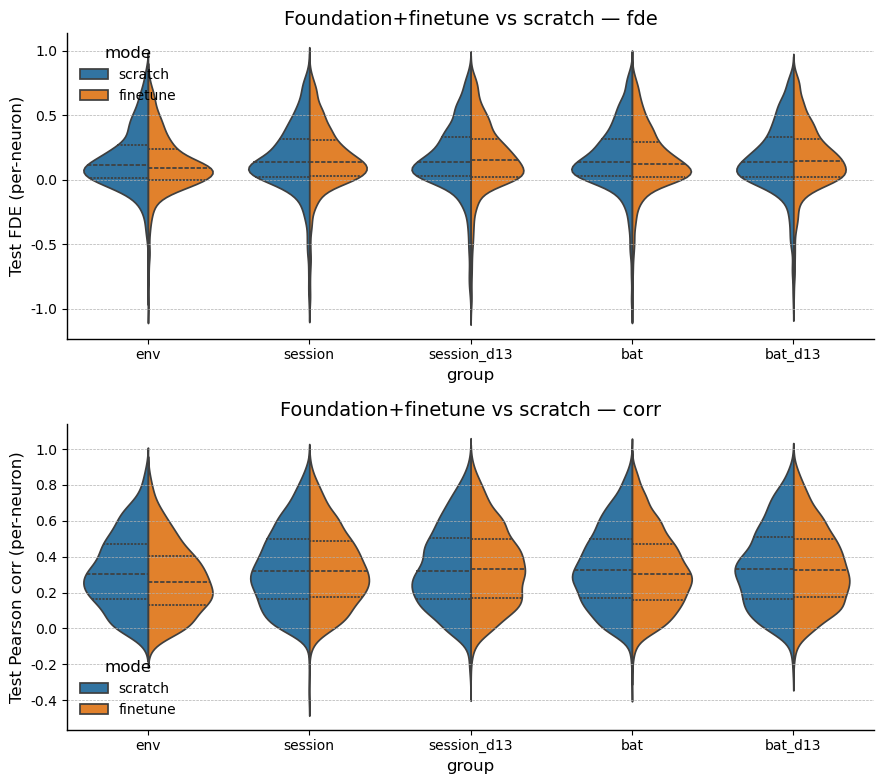

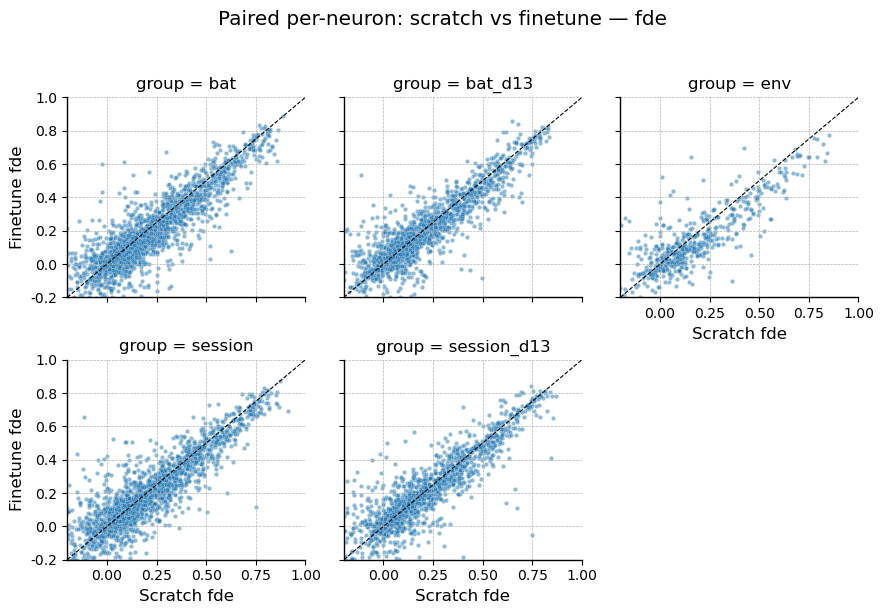

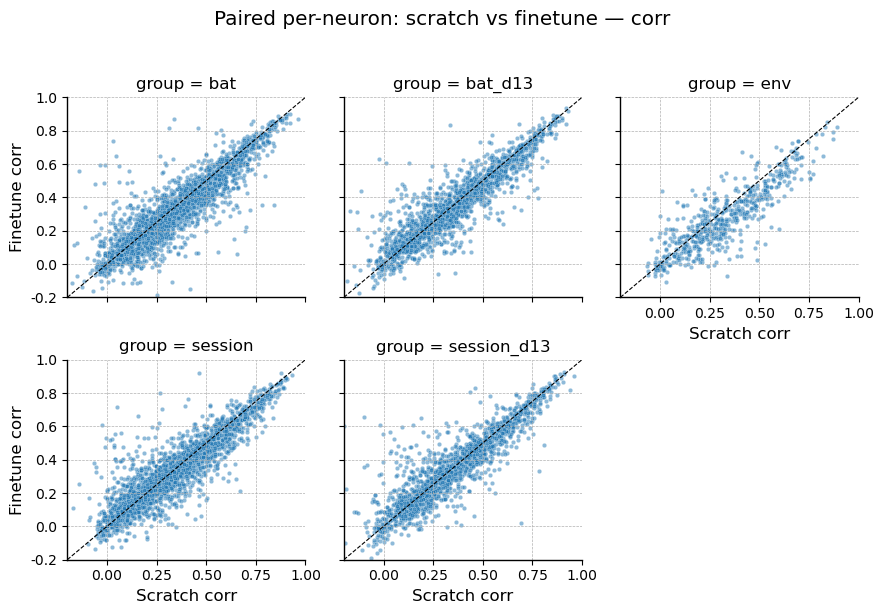

In [15]:
def load_all_results():
    dfs = []
    for g in ('env', 'session', 'session_d13', 'bat', 'bat_d13'):
        p = os.path.join(OUT_ROOT, g, f'results_{g}.pkl')
        if os.path.exists(p):
            dfs.append(pd.read_pickle(p))
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


METRICS = [
    ('fde',  'Test FDE (per-neuron)',          (-0.2, 1.0)),
    ('corr', 'Test Pearson corr (per-neuron)', (-0.2, 1.0)),
]


def crop_for_plot(df, metric):
    """Standing rule: always pre-filter to fde > -1 before plotting FDE."""
    return df[df['fde'] > -1] if metric == 'fde' else df


df_all = load_all_results()
if not df_all.empty:
    fig, axes = plt.subplots(len(METRICS), 1, figsize=(9, 4 * len(METRICS)))
    for ax, (metric, ylabel, _) in zip(np.atleast_1d(axes), METRICS):
        sub = crop_for_plot(df_all, metric)
        sns.violinplot(data=sub, x='group', y=metric, hue='mode',
                       split=True, inner='quartile', ax=ax)
        ax.set_ylabel(ylabel)
        ax.set_title(f'Foundation+finetune vs scratch — {metric}')
    plt.tight_layout()

    for metric, _, (lo, hi) in METRICS:
        src = crop_for_plot(df_all, metric)
        pivot = (src.pivot_table(index=['group', 'heldout', 'target_session', 'neuron_idx'],
                                  columns='mode', values=metric)
                 .reset_index())
        pivot = pivot.dropna(subset=['finetune', 'scratch'])
        if pivot.empty:
            continue
        g = sns.FacetGrid(pivot, col='group', col_wrap=3, height=3, sharex=True, sharey=True)
        g.map_dataframe(sns.scatterplot, x='scratch', y='finetune', alpha=0.5, s=10)
        for ax in g.axes.flat:
            ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
            ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        g.set_axis_labels(f'Scratch {metric}', f'Finetune {metric}')
        g.fig.suptitle(f'Paired per-neuron: scratch vs finetune — {metric}', y=1.02)
        plt.tight_layout()
else:
    print('No results on disk yet.')

# Paired statistics: finetune vs scratch

Paired comparisons at two aggregation levels:
1. **Neuron level** \u2014 pair `(target_session, neuron_idx)` across modes, test per-neuron FDE difference.
2. **Session level** \u2014 take median FDE across neurons within each target session, pair across modes.

Wilcoxon signed-rank is the primary test (non-parametric, robust to extreme FDE tails). Paired t on FDE clipped to [-1, 1] is included for magnitude intuition.

In [16]:
from scipy.stats import wilcoxon, ttest_rel


def paired_stats_neuron(df, metric='fde'):
    """Per-neuron paired Finetune-vs-Scratch stats on `metric`, broken down by group."""
    pair = (df.pivot_table(index=['group', 'heldout', 'target_session', 'neuron_idx'],
                            columns='mode', values=metric)
              .reset_index())
    pair = pair.dropna(subset=['finetune', 'scratch'])
    pair = pair[np.isfinite(pair['finetune']) & np.isfinite(pair['scratch'])]
    rows = []
    for group, sub in pair.groupby('group'):
        d = sub['finetune'] - sub['scratch']
        w2 = wilcoxon(d, alternative='two-sided')
        w_gt = wilcoxon(d, alternative='greater')  # H1: finetune > scratch
        t_clip = ttest_rel(sub['finetune'].clip(-1, 1), sub['scratch'].clip(-1, 1))
        rows.append(dict(
            group=group,
            n_neurons=len(sub),
            median_finetune=sub['finetune'].median(),
            median_scratch=sub['scratch'].median(),
            median_diff=d.median(),
            frac_finetune_wins=(d > 0).mean(),
            wilcoxon_W=w2.statistic,
            wilcoxon_p_two=w2.pvalue,
            wilcoxon_p_ft_gt=w_gt.pvalue,
            t_clip=t_clip.statistic,
            t_clip_p=t_clip.pvalue,
        ))
    return pd.DataFrame(rows)


def paired_stats_session(df, metric='fde'):
    """Session-level paired stats: median `metric` per target session, paired across modes."""
    sess = (df.groupby(['group', 'heldout', 'target_session', 'mode'])[metric]
              .median().unstack('mode').reset_index())
    sess = sess.dropna(subset=['finetune', 'scratch'])
    rows = []
    for group, sub in sess.groupby('group'):
        d = sub['finetune'] - sub['scratch']
        if len(sub) >= 1:
            try:
                w2 = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
                w_gt = wilcoxon(d, alternative='greater', zero_method='wilcox')
                wp2, wpgt, wW = w2.pvalue, w_gt.pvalue, w2.statistic
            except ValueError:
                wp2, wpgt, wW = np.nan, np.nan, np.nan
            t = ttest_rel(sub['finetune'], sub['scratch']) if len(sub) > 1 else None
        rows.append(dict(
            group=group,
            n_sessions=len(sub),
            mean_finetune=sub['finetune'].mean(),
            mean_scratch=sub['scratch'].mean(),
            mean_diff=d.mean(),
            frac_sessions_finetune_wins=(d > 0).mean(),
            wilcoxon_W=wW,
            wilcoxon_p_two=wp2,
            wilcoxon_p_ft_gt=wpgt,
            t_stat=(t.statistic if t is not None else np.nan),
            t_p=(t.pvalue if t is not None else np.nan),
        ))
    return pd.DataFrame(rows), sess


df_all = load_all_results()
if df_all.empty:
    print('No results on disk yet.')
else:
    for metric in ('fde', 'corr'):
        print(f'################  metric = {metric}  ################')
        neuron_stats = paired_stats_neuron(df_all, metric=metric)
        session_stats, session_table = paired_stats_session(df_all, metric=metric)
        print(f'=== Per-group neuron-level paired stats ({metric}) ===')
        display(neuron_stats.round(4))
        print()
        print(f'=== Per-group session-level paired stats ({metric}) ===')
        display(session_stats.round(4))
        print()
        print(f'=== Session medians ({metric}) by group, heldout, target_session ===')
        display(session_table.round(4))
        print()

################  metric = fde  ################
=== Per-group neuron-level paired stats (fde) ===


,group,n_neurons,median_finetune,median_scratch,median_diff,frac_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_clip,t_clip_p
0,bat,2253,0.1193,0.1333,-0.0216,0.3813,957574.0,0.0000,1.0000,-2.9335,0.0034
1,bat_d13,1695,0.1393,0.1329,-0.0067,0.4720,662091.0,0.0050,0.9975,0.9073,0.3644
2,env,558,0.0889,0.1092,-0.0415,0.3100,47042.0,0.0000,1.0000,-6.0601,0.0000
3,session,2253,0.1341,0.1293,-0.0093,0.4456,1140385.0,0.0000,1.0000,1.0467,0.2954
4,session_d13,1695,0.1427,0.1344,-0.0046,0.4737,693486.0,0.2113,0.8944,2.5978,0.0095



=== Per-group session-level paired stats (fde) ===


,group,n_sessions,mean_finetune,mean_scratch,mean_diff,frac_sessions_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_stat,t_p
0,bat,18,0.1545,0.1712,-0.0167,0.2222,37.0,0.0342,0.9848,-2.0018,0.0615
1,bat_d13,14,0.1786,0.1744,0.0042,0.5000,52.0,1.0000,0.5242,0.3574,0.7265
2,env,4,0.1069,0.1305,-0.0236,0.2500,2.0,0.3750,0.8750,-1.0952,0.3535
3,session,18,0.1675,0.1696,-0.0020,0.5556,78.0,0.7660,0.6331,-0.2243,0.8252
4,session_d13,14,0.1779,0.1733,0.0046,0.4286,36.0,0.3258,0.8521,0.2811,0.7831



=== Session medians (fde) by group, heldout, target_session ===


...

,group,n_neurons,median_finetune,median_scratch,median_diff,frac_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_clip,t_clip_p
0,bat,2253,0.3054,0.3249,-0.0177,0.3897,906670.0,0.0000,1.0000,-7.4885,0.0000
1,bat_d13,1695,0.3253,0.3293,-0.0064,0.4466,640302.5,0.0013,0.9994,-0.8836,0.3770
2,env,558,0.2613,0.3024,-0.0459,0.2867,39475.0,0.0000,1.0000,-9.5469,0.0000
3,session,2253,0.3214,0.3188,-0.0075,0.4416,1127417.0,0.0001,1.0000,-0.1780,0.8588
4,session_d13,1695,0.3301,0.3175,-0.0030,0.4737,671884.0,0.1021,0.9490,1.5662,0.1175



=== Per-group session-level paired stats (corr) ===


,group,n_sessions,mean_finetune,mean_scratch,mean_diff,frac_sessions_finetune_wins,wilcoxon_W,wilcoxon_p_two,wilcoxon_p_ft_gt,t_stat,t_p
0,bat,18,0.3342,0.3537,-0.0195,0.2222,34.0,0.0237,0.9896,-2.2539,0.0377
1,bat_d13,14,0.3535,0.3585,-0.0050,0.3571,43.0,0.5830,0.7292,-0.4693,0.6466
2,env,4,0.2732,0.3194,-0.0461,0.2500,1.0,0.2500,0.9375,-2.3527,0.1001
3,session,18,0.3467,0.3475,-0.0008,0.3333,61.0,0.3038,0.8581,-0.0788,0.9381
4,session_d13,14,0.3620,0.3598,0.0021,0.5000,49.0,0.8552,0.5961,0.2228,0.8272



=== Session medians (corr) by group, heldout, target_session ===


mode,group,heldout,target_session,finetune,scratch
0,bat,00000,Dataset_3_00000_240402,0.3484,0.3314
1,bat,00000,Dataset_3_00000_240403,0.4267,0.4572
2,bat,00000,Dataset_3_00000_240404,0.3559,0.3696
3,bat,00000,Dataset_3_00000_240405,0.4002,0.4036
4,bat,14445,Dataset_2_14445_231208,0.2796,0.3609
...,...,...,...,...,...
63,session_d13,Dataset_3_14543_240421,Dataset_3_14543_240421,0.4349,0.4874
64,session_d13,Dataset_3_29959_240402,Dataset_3_29959_240402,0.2403,0.2292
65,session_d13,Dataset_3_29959_240403,Dataset_3_29959_240403,0.3258,0.3454
66,session_d13,Dataset_3_29959_240404,Dataset_3_29959_240404,0.3492,0.3252


# Scaling with number of training sessions

For each universe (`SESSIONS` with 18, `SESSIONS_D13` with 14) we train end-to-end models on session counts $N \in \{2, 4, 8, N_\text{full}\}$ and compare against the $N=1$ scratch models already saved by the session sweeps. $N \in \{2,4,8\}$ uses **5 different random subsamples** of sessions per value; $N_\text{full}$ is deterministic (one model trained on the full universe). Each trained model scores one FDE value per included session (evaluated on that session's test split), so each target session appears in $\sim 5 \cdot N / N_\text{full}$ subsamples on average at $N \in \{2,4,8\}$.

In [17]:
def stratified_subsamples(universe, N, n_samples, rng):
    """Draw n_samples size-N subsets from `universe` such that every session
    appears in at least one subset.

    Stage 1: round-robin anchors \u2014 sample i anchors universe[i % N_full] (shuffled order),
             remaining N-1 slots filled uniformly without replacement from the rest.
    Stage 2: coverage repair \u2014 for each session still uncovered, find a subset where we can
             swap it in for a session that appears in >= 1 other subset (so coverage never drops).
    """
    universe = list(universe)
    N_full = len(universe)
    assert N <= N_full

    anchors = list(universe)
    rng.shuffle(anchors)
    samples = []
    for i in range(n_samples):
        anchor = anchors[i % N_full]
        others_pool = [s for s in universe if s != anchor]
        rest = list(rng.choice(others_pool, size=N - 1, replace=False))
        samples.append(sorted([anchor] + rest))

    covered = set().union(*samples) if samples else set()
    missing = sorted(set(universe) - covered)

    for m in missing:
        best = None  # (subset_idx, slot_idx, count_elsewhere)
        for si, sub in enumerate(samples):
            if m in sub:
                continue
            for ji, s in enumerate(sub):
                count_elsewhere = sum(1 for oi, osub in enumerate(samples)
                                      if oi != si and s in osub)
                if count_elsewhere >= 1 and (best is None or count_elsewhere > best[2]):
                    best = (si, ji, count_elsewhere)
        if best is None:
            raise RuntimeError(f'Cannot insert missing session {m} without dropping coverage')
        si, ji, _ = best
        samples[si][ji] = m
        samples[si] = sorted(samples[si])

    # sanity
    assert set().union(*samples) == set(universe), 'coverage repair failed'
    return samples


def run_scaling_sweep(group_name, scratch_group_name, universe_sessions,
                       sizes=(2, 4, 8), n_samples=10, seed=SEED,
                       max_workers=MAX_WORKERS):
    """
    Scaling curve: train models on size-N subsets of `universe_sessions` (n_samples stratified
    subsamples each, guaranteed to cover every session) plus the full universe.
    Evaluate each trained readout on its own session's test split.
    N=1 baseline is read from the saved `scratch_group_name` scratch checkpoints (no retraining).
    """
    universe = list(universe_sessions)
    N_full = len(universe)
    out_dir = os.path.join(OUT_ROOT, f'scaling_{group_name}')
    os.makedirs(out_dir, exist_ok=True)
    rows = []

    # ---- N=1: reuse saved scratch checkpoints from the session sweep ----
    for t in universe:
        scratch_path = ckpt_path(scratch_group_name, t, suffix=f'__{t}_scratch')
        if not os.path.exists(scratch_path):
            print(f'  [scaling_{group_name}] MISSING scratch for {t}: {scratch_path}')
            continue
        model = build_bat_former({t: unit_num_dict[t]}, behavior_dim)
        model.load_state_dict(torch.load(scratch_path, map_location=DEVICE))
        model.to(DEVICE)
        fde, pc = eval_on_session(model, t, dataloaders, split='test')
        for i, (f, c) in enumerate(zip(fde, pc)):
            rows.append(dict(scaling_group=group_name, n_sessions=1, sample_id=0,
                             target_session=t, neuron_idx=i,
                             fde=float(f), corr=float(c)))

    # ---- build stratified (N, sample_id) -> session subset ----
    rng = np.random.default_rng(seed)
    subsamples = {}
    for N in sizes:
        subs = stratified_subsamples(universe, N, n_samples, rng)
        for sid, sub in enumerate(subs):
            subsamples[(N, sid)] = sub
    subsamples[(N_full, 0)] = list(universe)

    # ---- train each subset in parallel ----
    tasks = []
    for (N, sid), sub in subsamples.items():
        path = os.path.join(out_dir,
            f'bat_former_seed_{seed}_wd_sweep_scaling_{group_name}_N{N}_s{sid}.pth')
        tid = f'SCAL:{group_name}:N{N}:s{sid}'
        tasks.append((tid, lambda src=list(sub), p=path: train_foundation(src, p, seed=seed)))
    results = run_tasks_parallel(tasks, max_workers=max_workers, label=f'scaling_{group_name}')

    # ---- evaluate every (model, readout) on that readout's own session ----
    for (N, sid), sub in subsamples.items():
        r = results.get(f'SCAL:{group_name}:N{N}:s{sid}')
        if r is None:
            continue
        _, model = r
        for t in sub:
            fde, pc = eval_on_session(model, t, dataloaders, split='test')
            for i, (f, c) in enumerate(zip(fde, pc)):
                rows.append(dict(scaling_group=group_name, n_sessions=N, sample_id=sid,
                                 target_session=t, neuron_idx=i,
                                 fde=float(f), corr=float(c)))

    df = pd.DataFrame(rows)
    df_path = os.path.join(out_dir, f'results_scaling_{group_name}.pkl')
    df.to_pickle(df_path)
    print(f'Saved {len(df)} rows to {df_path}')
    return df

In [18]:
RUN_SCALING_SESSION = False  # 5*3 + 1 = 16 new foundation trainings over SESSIONS (18)

if RUN_SCALING_SESSION:
    df_scaling_session = run_scaling_sweep(
        group_name='session',
        scratch_group_name='session',
        universe_sessions=SESSIONS,
    )

In [19]:
RUN_SCALING_SESSION_D13 = False  # 5*3 + 1 = 16 new foundation trainings over SESSIONS_D13 (14)

if RUN_SCALING_SESSION_D13:
    df_scaling_d13 = run_scaling_sweep(
        group_name='session_d13',
        scratch_group_name='session_d13',
        universe_sessions=SESSIONS_D13,
    )

## Scaling analysis: plots + paired stats

- **Curve**: per-session median FDE (across neurons) at each $N$, with each subsample contributing one point; overlaid mean per $N$.
- **Paired stats**: for each $N \in \{2,4,8,N_\text{full}\}$, compare per-session median FDE against the matching $N=1$ scratch value for the same target session. With 5 subsamples, a target session contributes up to 5 paired comparisons per $N$ (or 0 if it was never drawn); we use Wilcoxon signed-rank + paired t on those pairs.

NameError: name 'crop_for_plot' is not defined

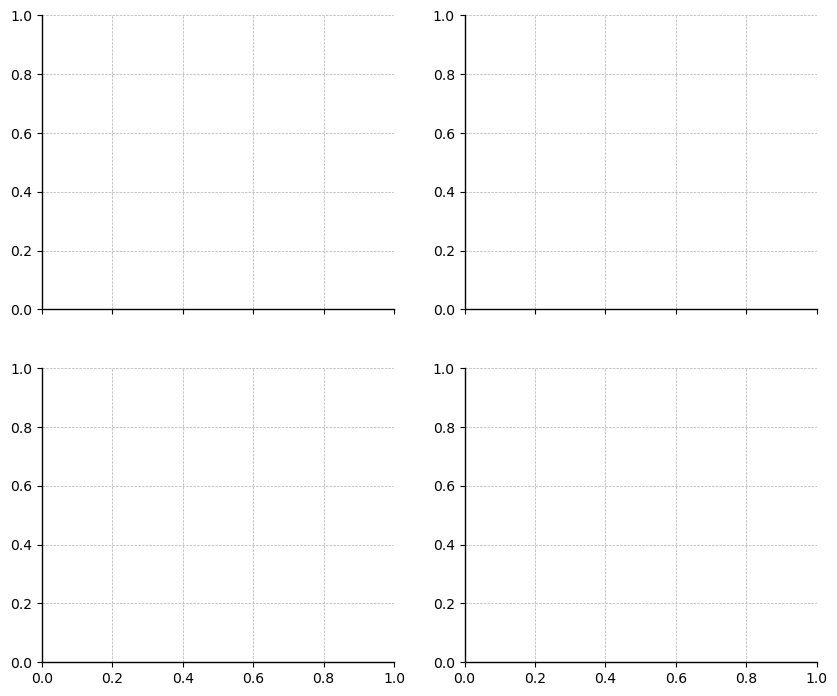

In [10]:
def load_scaling_results():
    dfs = []
    for g in ('session', 'session_d13'):
        p = os.path.join(OUT_ROOT, f'scaling_{g}', f'results_scaling_{g}.pkl')
        if os.path.exists(p):
            dfs.append(pd.read_pickle(p))
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


def scaling_per_target(df, metric='fde'):
    """Median `metric` across neurons per (group, N, sample_id, target), then mean over subsamples
    that contained the target. One value per (group, N, target) — paired across N by target."""
    med = (df.groupby(['scaling_group', 'n_sessions', 'sample_id', 'target_session'])[metric]
             .median().reset_index(name=f'{metric}_median'))
    per_T = (med.groupby(['scaling_group', 'n_sessions', 'target_session'])[f'{metric}_median']
                .agg(['mean', 'count']).reset_index()
                .rename(columns={'mean': metric, 'count': 'n_subsamples'}))
    return per_T


def scaling_paired_stats(per_T, metric='fde'):
    """Pair per-target `metric` at N>1 vs N=1 scratch on the same target; Wilcoxon + paired t."""
    base = (per_T[per_T['n_sessions'] == 1]
            .set_index(['scaling_group', 'target_session'])[metric]
            .rename(f'{metric}_scratch'))
    rows = []
    for (grp, N), sub in per_T[per_T['n_sessions'] > 1].groupby(['scaling_group', 'n_sessions']):
        joined = sub.join(base, on=['scaling_group', 'target_session']).dropna(subset=[metric, f'{metric}_scratch'])
        d = joined[metric] - joined[f'{metric}_scratch']
        try:
            w2 = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
            w_gt = wilcoxon(d, alternative='greater', zero_method='wilcox')
            wW, wp2, wpgt = w2.statistic, w2.pvalue, w_gt.pvalue
        except ValueError:
            wW = wp2 = wpgt = np.nan
        t = ttest_rel(joined[metric], joined[f'{metric}_scratch']) if len(joined) > 1 else None
        rows.append(dict(
            scaling_group=grp, n_sessions=int(N),
            n_targets=len(joined),
            mean_N=joined[metric].mean(),
            mean_scratch=joined[f'{metric}_scratch'].mean(),
            mean_diff=d.mean(),
            frac_targets_N_better=(d > 0).mean(),
            wilcoxon_W=wW, wilcoxon_p_two=wp2, wilcoxon_p_N_better=wpgt,
            t_stat=(t.statistic if t is not None else np.nan),
            t_p=(t.pvalue if t is not None else np.nan),
        ))
    return pd.DataFrame(rows)


def p_to_stars(p):
    if p is None or not np.isfinite(p):
        return ''
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'n.s.'


SCALING_METRICS = [
    ('fde',  'FDE on target session test split (higher = better)'),
    ('corr', 'Pearson corr on target session test split (higher = better)'),
]


df_sc = load_scaling_results()
if df_sc.empty:
    print('No scaling results on disk yet. Flip RUN_SCALING_* flags and rerun.')
else:
    groups = sorted(df_sc['scaling_group'].unique())
    fig, axes = plt.subplots(len(SCALING_METRICS), len(groups),
                              figsize=(5 * len(groups), 4.2 * len(SCALING_METRICS)),
                              sharex='col', squeeze=False)

    for row, (metric, ylabel) in enumerate(SCALING_METRICS):
        src = crop_for_plot(df_sc, metric)
        per_T = scaling_per_target(src, metric=metric)
        stats = scaling_paired_stats(per_T, metric=metric)
        for ax, grp in zip(axes[row], groups):
            sub = per_T[per_T['scaling_group'] == grp]
            ns = sorted(sub['n_sessions'].unique())
            wide = sub.pivot(index='target_session', columns='n_sessions', values=metric).reindex(columns=ns)
            for _, r in wide.iterrows():
                ax.plot(ns, r.values, color='gray', alpha=0.4, lw=0.8, marker='.', ms=4)
            means = [sub[sub['n_sessions'] == n][metric].mean() for n in ns]
            ax.plot(ns, means, color='C3', lw=2.5, marker='o', ms=7, label='mean across targets')

            y_top = sub[metric].max()
            y_bot = sub[metric].min()
            y_txt = y_top + 0.08 * (y_top - y_bot)
            gs = stats[stats['scaling_group'] == grp].set_index('n_sessions')
            for n in ns:
                if n == 1:
                    continue
                p = gs.loc[n, 'wilcoxon_p_two'] if n in gs.index else np.nan
                ax.text(n, y_txt, p_to_stars(p), ha='center', va='bottom', fontsize=11)
            ax.set_ylim(top=y_top + 0.18 * (y_top - y_bot))

            ax.set_xscale('log', base=2)
            ax.set_xticks(ns); ax.set_xticklabels(ns)
            ax.set_xlabel('# training sessions (T in training set)')
            if row == 0:
                ax.set_title(grp)
            ax.legend(frameon=False, loc='lower right')
        axes[row, 0].set_ylabel(ylabel)

        print(f'=== Scaling paired stats ({metric}; H1: N-model mean > scratch on same target) ===')
        display(stats.round(4))

    fig.suptitle('Scaling: same test data, varying training-set size (stars: Wilcoxon 2-sided vs N=1)')
    plt.tight_layout()

# Full vs transfer vs scratch (neuron-level violins)

Per-neuron test metrics under three training regimes, on the 18-session sweep:
- **full (N=18)** — foundation trained on all 18 sessions, evaluated on each session's own test split (from `scaling_session` at N=18).
- **transfer** — foundation trained on the 17 non-target sessions, target readout fine-tuned (frozen core).
- **scratch** — single-session model trained only on the target session.

All three share the same per-session train/valid/test split, so the violins are over the same set of (session, neuron) pairs.

Neuron counts per condition:


condition
full (N=18)    2253
scratch        2253
transfer       2253
Name: n_neurons, dtype: int64

Medians:


,corr,fde
condition,,
full (N=18),0.3151,0.1290
scratch,0.3188,0.1293
transfer,0.3214,0.1341


Paired-difference summary (neuron-level):


,metric,contrast,n,median,mean,frac_pos,wilcoxon_W,wilcoxon_p_two
0,corr,full − scratch,2253,-0.0083,-0.0033,0.4372,1079527.5,0.0000
1,corr,full − transfer,2253,-0.0019,-0.0029,0.4758,1178687.5,0.0225
2,corr,scratch − transfer,2253,0.0075,0.0004,0.5499,1127417.0,0.0001
3,fde,full − scratch,2197,-0.0081,0.0014,0.4502,1079865.0,0.0000
4,fde,full − transfer,2206,-0.0012,-0.0000,0.4918,1194410.0,0.4470
5,fde,scratch − transfer,2197,0.0091,-0.0007,0.5530,1090216.0,0.0001


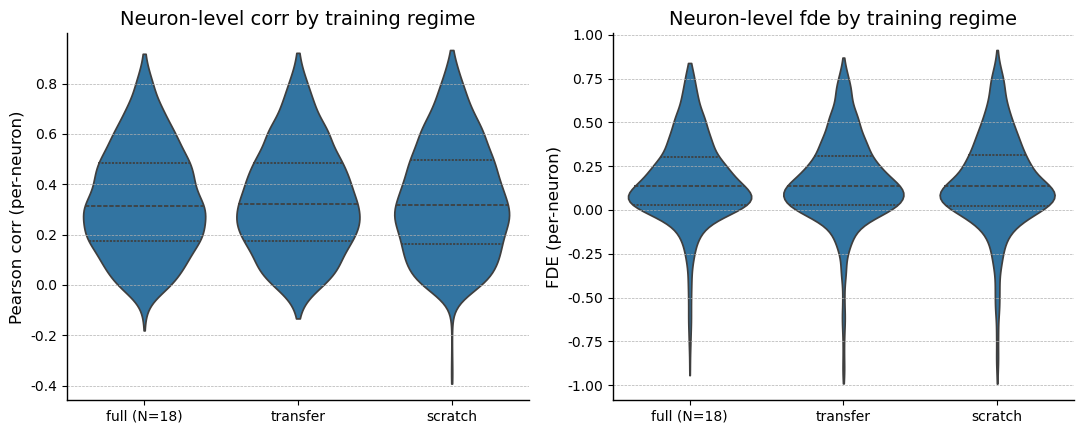

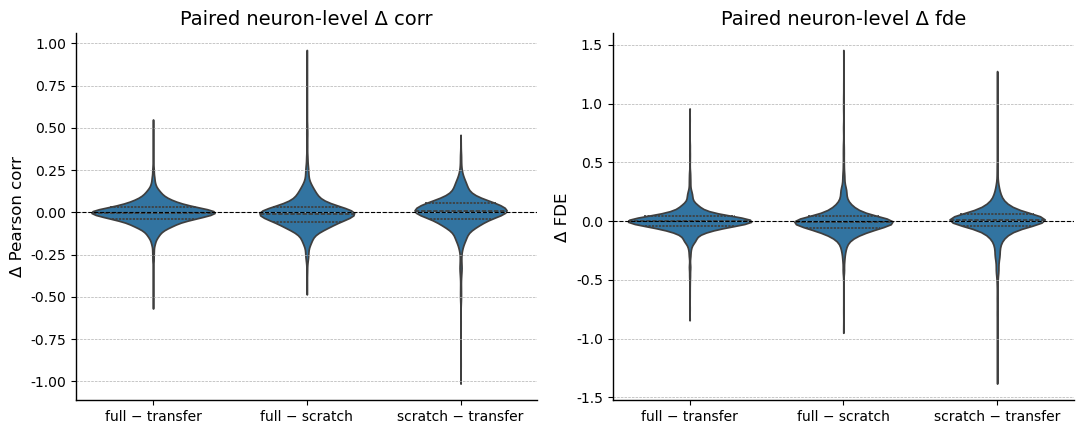

In [21]:
df_all = load_all_results()
df_sc = load_scaling_results()

N_FULL = len(SESSIONS)  # 18

frames = []
if not df_sc.empty:
    full = df_sc[(df_sc['scaling_group'] == 'session') & (df_sc['n_sessions'] == N_FULL)][
        ['target_session', 'neuron_idx', 'fde', 'corr']].copy()
    if not full.empty:
        full['condition'] = f'full (N={N_FULL})'
        frames.append(full)
if not df_all.empty:
    for mode, label in [('finetune', 'transfer'), ('scratch', 'scratch')]:
        sub = df_all[(df_all['group'] == 'session') & (df_all['mode'] == mode)][
            ['target_session', 'neuron_idx', 'fde', 'corr']].copy()
        if not sub.empty:
            sub['condition'] = label
            frames.append(sub)

if not frames:
    print('Not enough data on disk — need scaling_session (N=18) and session sweep results.')
else:
    df_cmp = pd.concat(frames, ignore_index=True)
    full_label = f'full (N={N_FULL})'
    order = [c for c in [full_label, 'transfer', 'scratch'] if c in df_cmp['condition'].unique()]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, metric, ylabel in zip(
        axes,
        ('corr', 'fde'),
        ('Pearson corr (per-neuron)', 'FDE (per-neuron)'),
    ):
        sns.violinplot(data=crop_for_plot(df_cmp, metric),
                       x='condition', y=metric, order=order,
                       inner='quartile', ax=ax, cut=0)
        ax.set_xlabel('')
        ax.set_ylabel(ylabel)
        ax.set_title(f'Neuron-level {metric} by training regime')
    plt.tight_layout()

    print('Neuron counts per condition:')
    display(df_cmp.groupby('condition').size().rename('n_neurons'))
    print('Medians:')
    display(df_cmp.groupby('condition')[['corr', 'fde']].median().round(4))

    # ---- Paired neuron-level differences ----
    diff_specs = [
        ('full − transfer',    full_label, 'transfer'),
        ('full − scratch',     full_label, 'scratch'),
        ('scratch − transfer', 'scratch',  'transfer'),
    ]
    diff_frames = []
    pivots = {
        m: crop_for_plot(df_cmp, m).pivot_table(
            index=['target_session', 'neuron_idx'], columns='condition', values=m)
        for m in ('corr', 'fde')
    }
    for metric, p in pivots.items():
        for label, a, b in diff_specs:
            if a not in p.columns or b not in p.columns:
                continue
            d = (p[a] - p[b]).dropna().rename('diff').reset_index()
            d['contrast'] = label
            d['metric'] = metric
            diff_frames.append(d)

    if diff_frames:
        df_diff = pd.concat(diff_frames, ignore_index=True)

        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        for ax, metric, ylabel in zip(
            axes,
            ('corr', 'fde'),
            ('Δ Pearson corr', 'Δ FDE'),
        ):
            sns.violinplot(data=df_diff[df_diff['metric'] == metric],
                           x='contrast', y='diff',
                           order=[s[0] for s in diff_specs],
                           inner='quartile', ax=ax, cut=0)
            ax.axhline(0, color='k', lw=0.8, ls='--')
            ax.set_xlabel('')
            ax.set_ylabel(ylabel)
            ax.set_title(f'Paired neuron-level Δ {metric}')
        plt.tight_layout()

        rows = []
        for (metric, contrast), sub in df_diff.groupby(['metric', 'contrast']):
            d = sub['diff'].values
            try:
                w = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
                wW, wp = float(w.statistic), float(w.pvalue)
            except ValueError:
                wW, wp = np.nan, np.nan
            rows.append(dict(
                metric=metric, contrast=contrast, n=len(d),
                median=float(np.median(d)), mean=float(np.mean(d)),
                frac_pos=float((d > 0).mean()),
                wilcoxon_W=wW, wilcoxon_p_two=wp,
            ))
        print('Paired-difference summary (neuron-level):')
        display(pd.DataFrame(rows).round(4))

# 2 × 5 matrix: data fraction × training mode

**Universe:** the same **18 sessions** in `SESSIONS` used by the upstream
`session` and `scaling_session` sweeps — i.e. all sessions across **all
three datasets** (D1, D2, D3): 3 D1 sessions (bat 32622), 4 D2 sessions
(bats 14445 / 14611), and 11 D3 sessions (bats 14543 / 29959 / 00000).
Each of these 18 sessions takes a turn as the *target*; the other 17 are
*source* sessions.

For each target we evaluate **five** training regimes
(**full** / **frozen** / **lowlr** / **highlr** / **scratch**) at two
target-session training-data fractions: **100 %** and **25 %**.
All other 17 sessions stay at 100 %; the test set is always the target's
full test split.

The two `*lr` modes both unfreeze the transformer core during finetune
(non-target readouts stay frozen) but differ in how the core's LR
compares to the target readout's LR:

| mode      | core LR        | readout LR | how it differs from `frozen`        |
| ---       | ---            | ---        | ---                                 |
| `frozen`  | (frozen)       | `LR`       | core not trained                    |
| `lowlr`   | `0.1 × LR`     | `LR`       | core trained, but slower            |
| `highlr`  | `LR`           | `LR`       | core trained at the same LR         |

Already-trained checkpoints are reused when the cell matches:

| cell                       | source                                     |
| ---                        | ---                                        |
| `(full,  100%)`            | `scaling_session/…N18_s0.pth`              |
| `(frozen, 100%)`           | `session/…__{target}_finetune.pth`         |
| `(scratch, 100%)`          | `session/…__{target}_scratch.pth`          |

The remaining 7 cells (7 × 18 = 126 trainings) are new: the four 25 %
cells, plus `lowlr@100%`, `highlr@100%`, and `highlr@25%`. Per-target
foundation init for all three transfer modes comes from
`session/…{target}.pth` (held-out 17-session foundations already trained
upstream).

WD grids: `WD_GRID = [0.01, 0.1]` for full / frozen / lowlr / highlr;
the wider `WD_SCRATCH_GRID = [0.01, 0.1, 1.0]` for scratch only.


In [ ]:
from torch.utils.data import DataLoader, Subset
import copy as _copy
import tqdm as _tqdm

FRACTION_2X5 = 0.25
CORE_LR_FRAC = 0.1
TWOXFIVE_DIR = os.path.join(OUT_ROOT, 'twoxfive')
os.makedirs(TWOXFIVE_DIR, exist_ok=True)


def subsample_train_dataloader(dl, fraction, seed=SEED):
    """Return a new DataLoader using a fixed `fraction` of `dl.dataset`. Seeded so all
    four 25%-modes per target see exactly the same subset of training trajectories."""
    if fraction >= 1.0:
        return dl
    ds = dl.dataset
    n = len(ds)
    n_keep = max(1, int(round(fraction * n)))
    rng = np.random.default_rng(seed)
    indices = sorted(rng.choice(n, size=n_keep, replace=False).tolist())
    return DataLoader(
        Subset(ds, indices),
        batch_size=dl.batch_size, shuffle=True,
        collate_fn=getattr(dl, 'collate_fn', None),
        num_workers=getattr(dl, 'num_workers', 0),
        drop_last=getattr(dl, 'drop_last', False),
    )


def twoxfive_path(target, mode, fraction_pct):
    name = (f'bat_former_seed_{SEED}_wd_sweep_2x5_'
            f'frac{fraction_pct}_{mode}_{target}.pth')
    return os.path.join(TWOXFIVE_DIR, name)


def finetune_lowlr_trainer(
    model, dataloaders, device, target_session,
    core_lr_frac=CORE_LR_FRAC,
    n_epochs=200, lr=1e-2, weight_decay=0.0,
    loss_fn=None, valid_fn=None, valid_stat='mean',
    early_stopping_patience=None,
    save_model=False, model_name='best_lowlr_weights.pth',
    **_unused,
):
    """Fine-tune target readout at `lr` and the rest of the model (excluding other
    session readouts) at `core_lr_frac * lr`. Other readouts are frozen.

    Mirrors finetune_readout_trainer but adds the transformer core to the optimizer
    in a separate parameter group at the lower LR. Iterates only over
    `dataloaders['train'|'valid'][target_session]`.
    """
    model = model.to(device)
    loss_fn = loss_fn.to(device)
    target_param_ids = {id(p) for p in model.readouts[target_session].parameters()}
    other_readout_ids = {id(p) for sess, mod in model.readouts.items()
                         if sess != target_session for p in mod.parameters()}
    for p in model.parameters():
        p.requires_grad = id(p) not in other_readout_ids
    target_params = list(model.readouts[target_session].parameters())
    core_params = [p for p in model.parameters()
                   if id(p) not in target_param_ids
                   and id(p) not in other_readout_ids]
    optimizer = torch.optim.AdamW([
        {'params': core_params,   'lr': lr * core_lr_frac, 'weight_decay': weight_decay},
        {'params': target_params, 'lr': lr,                'weight_decay': weight_decay},
    ])

    best_score, best_weights = -np.inf, None
    val_scores, no_improve = [], 0
    train_loader = dataloaders['train'][target_session]
    valid_loader = dataloaders['valid'][target_session]

    for epoch in _tqdm.tqdm(range(n_epochs), desc=f'FT-LowLR[{target_session}]'):
        model.train()
        for sess, mod in model.readouts.items():
            if sess != target_session:
                mod.eval()
        for batch in train_loader:
            X = batch.behavior.to(device); y = batch.spike.to(device); mask = batch.mask.to(device)
            y_pred = model(target_session, X, mask)
            loss = loss_fn(y_pred[mask == 1.0], y[mask == 1.0])
            optimizer.zero_grad(); loss.backward(); optimizer.step()

        model.eval()
        y_v_list, y_p_list = [], []
        with torch.no_grad():
            for batch in valid_loader:
                X = batch.behavior.to(device); y = batch.spike.to(device); mask = batch.mask.to(device)
                y_pred = model(target_session, X, mask)
                y_v_list.append(y.detach()[mask == 1.0].cpu().numpy())
                y_p_list.append(y_pred.detach()[mask == 1.0].cpu().numpy())
        scores = valid_fn(np.vstack(y_v_list), np.vstack(y_p_list))
        val = float(np.nanmean(scores) if valid_stat == 'mean' else np.nanmedian(scores))
        val_scores.append(val)
        if val > best_score:
            best_score = val
            best_weights = _copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if early_stopping_patience and no_improve >= early_stopping_patience:
                print(f'Early stopping at epoch {epoch + 1}')
                break

    if save_model:
        torch.save(model.state_dict(), model_name)
    if best_weights is not None:
        model.load_state_dict(best_weights)
    return best_score, best_weights, val_scores

In [ ]:
def _sweep_wd_train_2x5(build_fn, dl_sub, save_path, n_epochs, mode,
                          target_session=None, wd_grid=WD_GRID,
                          core_lr_frac=CORE_LR_FRAC):
    """WD sweep dispatching to the right trainer for `mode`.
    mode in {'full','scratch'}:    bat_former_trainer
    mode == 'frozen':              finetune_readout_trainer
    mode in {'lowlr', 'highlr'}:   finetune_lowlr_trainer
        - 'lowlr'  uses the supplied `core_lr_frac` (default CORE_LR_FRAC = 0.1)
        - 'highlr' overrides it to 1.0 so the core trains at the readout's full LR
    """
    sweep = []
    for wd in wd_grid:
        sweep_save = wd_path(save_path, wd)
        model = build_fn()
        cfg = dict(
            model=model, dataloaders=dl_sub, device=DEVICE,
            n_epochs=n_epochs, lr=LR, weight_decay=wd,
            loss_fn=nn.PoissonNLLLoss(log_input=False),
            valid_fn=poisson_fde_population, valid_stat='median',
            early_stopping_patience=EARLY_STOP_PATIENCE,
            save_model=True, model_name=sweep_save,
        )
        if mode == 'frozen':
            cfg['target_session'] = target_session
            score, _, _ = finetune_readout_trainer(**cfg)
        elif mode in ('lowlr', 'highlr'):
            cfg['target_session'] = target_session
            cfg['core_lr_frac'] = 1.0 if mode == 'highlr' else core_lr_frac
            score, _, _ = finetune_lowlr_trainer(**cfg)
        else:
            score, _, _ = bat_former_trainer(**cfg)
        sweep.append((float(score), wd, sweep_save))
        del model
        torch.cuda.empty_cache()

    best_score, best_wd, best_sweep_path = max(sweep, key=lambda x: x[0])
    final_model = build_fn()
    final_model.load_state_dict(torch.load(best_sweep_path, map_location=DEVICE))
    final_model.to(DEVICE)
    torch.save(final_model.state_dict(), save_path)
    print(f'  [2x5 sweep] {os.path.basename(save_path)} best_wd={best_wd}  val={best_score:.4f}  '
          + '(' + ', '.join(f'wd={w}->{s:.4f}' for s, w, _ in sweep) + ')')
    return best_score, final_model, best_wd


def _foundation_path_for_target(target_session):
    """Canonical 17-session foundation checkpoint for `target_session` (held out)."""
    return ckpt_path('session', target_session)


def _build_for_finetune(target_session, foundation_path, seed=SEED):
    """Bat_Transformer with all 18 readouts; load 17 from `foundation_path`,
    fresh init for `target_session` readout."""
    unit_sub = {s: unit_num_dict[s] for s in SESSIONS}
    model = build_bat_former(unit_sub, behavior_dim, seed=seed)
    state = torch.load(foundation_path, map_location=DEVICE)
    target_prefix = f'readouts.{target_session}.'
    filtered = {k: v for k, v in state.items() if not k.startswith(target_prefix)}
    msg = model.load_state_dict(filtered, strict=False)
    assert not msg.unexpected_keys, msg.unexpected_keys
    other_missing = [k for k in msg.missing_keys if not k.startswith(target_prefix)]
    assert not other_missing, other_missing
    return model


def train_full_2x5(target, fraction, save_path, wd_grid=WD_GRID):
    """All 18 sessions in train/valid; target subsampled to `fraction`."""
    dl_sub = {
        'train': {s: dataloaders['train'][s] for s in SESSIONS},
        'valid': {s: dataloaders['valid'][s] for s in SESSIONS},
        'test':  {s: dataloaders['test'][s]  for s in SESSIONS},
    }
    if fraction < 1.0:
        dl_sub['train'][target] = subsample_train_dataloader(
            dataloaders['train'][target], fraction, seed=SEED)
    def build():
        return build_bat_former(unit_num_dict, behavior_dim, seed=SEED)
    return _sweep_wd_train_2x5(build, dl_sub, save_path,
                                n_epochs=N_EPOCHS_FOUNDATION,
                                mode='full', wd_grid=wd_grid)


def train_scratch_2x5(target, fraction, save_path, wd_grid=WD_SCRATCH_GRID):
    """Scratch on target only, subsampled to `fraction` of train."""
    target_train = subsample_train_dataloader(
        dataloaders['train'][target], fraction, seed=SEED)
    dl_sub = {
        'train': {target: target_train},
        'valid': {target: dataloaders['valid'][target]},
        'test':  {target: dataloaders['test'][target]},
    }
    unit_sub = {target: unit_num_dict[target]}
    def build():
        return build_bat_former(unit_sub, behavior_dim, seed=SEED)
    return _sweep_wd_train_2x5(build, dl_sub, save_path,
                                n_epochs=N_EPOCHS_SCRATCH,
                                mode='scratch', wd_grid=wd_grid)


def train_finetune_frozen_2x5(target, fraction, save_path, wd_grid=WD_GRID):
    """Frozen-core finetune of target readout at `fraction` of train."""
    foundation_path = _foundation_path_for_target(target)
    target_train = subsample_train_dataloader(
        dataloaders['train'][target], fraction, seed=SEED)
    dl_sub = {
        'train': {target: target_train},
        'valid': {target: dataloaders['valid'][target]},
        'test':  {target: dataloaders['test'][target]},
    }
    def build():
        m = _build_for_finetune(target, foundation_path)
        freeze_core_for_finetune(m, target)
        return m
    return _sweep_wd_train_2x5(build, dl_sub, save_path,
                                n_epochs=N_EPOCHS_FINETUNE,
                                mode='frozen', target_session=target,
                                wd_grid=wd_grid)


def _train_finetune_unfrozen_2x5(target, fraction, save_path, *, mode, wd_grid=WD_GRID):
    """Shared core for `lowlr` (core_lr_frac=CORE_LR_FRAC) and `highlr` (core_lr_frac=1.0).
    Both modes load the per-target foundation, leave the core trainable, and freeze
    only the non-target readouts (handled inside finetune_lowlr_trainer)."""
    assert mode in ('lowlr', 'highlr')
    foundation_path = _foundation_path_for_target(target)
    target_train = subsample_train_dataloader(
        dataloaders['train'][target], fraction, seed=SEED)
    dl_sub = {
        'train': {target: target_train},
        'valid': {target: dataloaders['valid'][target]},
        'test':  {target: dataloaders['test'][target]},
    }
    def build():
        return _build_for_finetune(target, foundation_path)
    return _sweep_wd_train_2x5(build, dl_sub, save_path,
                                n_epochs=N_EPOCHS_FINETUNE,
                                mode=mode, target_session=target,
                                wd_grid=wd_grid)


def train_finetune_lowlr_2x5(target, fraction, save_path, wd_grid=WD_GRID):
    """Low-LR finetune: core at CORE_LR_FRAC*LR, target readout at LR."""
    return _train_finetune_unfrozen_2x5(target, fraction, save_path,
                                          mode='lowlr', wd_grid=wd_grid)


def train_finetune_highlr_2x5(target, fraction, save_path, wd_grid=WD_GRID):
    """High-LR finetune: core at LR (= readout LR; no downward adjustment).
    Conceptually equivalent to `lowlr` minus the LR scaling — useful as the
    upper-bound counterpart to `lowlr` and a contrast to `frozen`."""
    return _train_finetune_unfrozen_2x5(target, fraction, save_path,
                                          mode='highlr', wd_grid=wd_grid)


In [ ]:
MODES_2X5     = ('full', 'frozen', 'lowlr', 'highlr', 'scratch')
FRACTIONS_2X5 = (1.0, 0.25)


def _scaling_n18_path():
    return os.path.join(OUT_ROOT, 'scaling_session',
                        f'bat_former_seed_{SEED}_wd_sweep_scaling_session_N18_s0.pth')


def _existing_session_sweep_path(target, kind):
    """kind in {'finetune', 'scratch'} — naming from the `session` group sweep."""
    return ckpt_path('session', target, suffix=f'__{target}_{kind}')


def _model_path_2x5(target, mode, fraction):
    """Where the (target, mode, fraction) checkpoint lives. Reuses existing
    session-sweep checkpoints for the three (mode, 100%) cells."""
    if fraction == 1.0:
        if mode == 'full':    return _scaling_n18_path()
        if mode == 'frozen':  return _existing_session_sweep_path(target, 'finetune')
        if mode == 'scratch': return _existing_session_sweep_path(target, 'scratch')
    fraction_pct = int(round(fraction * 100))
    return twoxfive_path(target, mode, fraction_pct)


def _train_one_2x5(target, mode, fraction, save_path):
    if mode == 'full':
        train_full_2x5(target, fraction, save_path)
    elif mode == 'frozen':
        train_finetune_frozen_2x5(target, fraction, save_path)
    elif mode == 'lowlr':
        train_finetune_lowlr_2x5(target, fraction, save_path)
    elif mode == 'highlr':
        train_finetune_highlr_2x5(target, fraction, save_path)
    elif mode == 'scratch':
        train_scratch_2x5(target, fraction, save_path)


def _eval_2x5(target, mode, model_path):
    """Load checkpoint and return (per-neuron FDE, per-neuron corr) on target's test split."""
    if mode == 'scratch':
        unit_sub = {target: unit_num_dict[target]}
    else:
        unit_sub = unit_num_dict  # full / frozen / lowlr / highlr checkpoints carry all 18 readouts
    model = build_bat_former(unit_sub, behavior_dim)
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.to(DEVICE)
    fde, pc = eval_on_session(model, target, dataloaders, split='test')
    del model
    torch.cuda.empty_cache()
    return fde, pc


def run_2x5_sweep(targets=SESSIONS, max_workers=MAX_WORKERS):
    n_targets = len(targets)
    n_cells_total = n_targets * len(MODES_2X5) * len(FRACTIONS_2X5)
    # ---- Wave 1: train every cell whose checkpoint is missing ----
    train_tasks = []
    for target in targets:
        for fraction in FRACTIONS_2X5:
            for mode in MODES_2X5:
                save_path = _model_path_2x5(target, mode, fraction)
                if os.path.exists(save_path):
                    continue
                tid = f'2x5:{target}:f{int(fraction*100)}:{mode}'
                fn = (lambda t=target, fr=fraction, m=mode, p=save_path:
                      _train_one_2x5(t, m, fr, p))
                train_tasks.append((tid, fn))
    print(f'2x5: {len(train_tasks)} cells need training; '
          f'{n_cells_total - len(train_tasks)} reused from disk.')
    if train_tasks:
        run_tasks_parallel(train_tasks, max_workers=max_workers, label='2x5')

    # ---- Wave 2: evaluate every cell ----
    rows = []
    for target in targets:
        for fraction in FRACTIONS_2X5:
            for mode in MODES_2X5:
                model_path = _model_path_2x5(target, mode, fraction)
                if not os.path.exists(model_path):
                    print(f'  MISSING after training: {model_path}')
                    continue
                fde, pc = _eval_2x5(target, mode, model_path)
                fr_pct = int(round(fraction * 100))
                for i, (f, c) in enumerate(zip(fde, pc)):
                    rows.append(dict(
                        target_session=target, mode=mode, fraction_pct=fr_pct,
                        neuron_idx=i, fde=float(f), corr=float(c),
                    ))

    df = pd.DataFrame(rows)
    out_path = os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl')
    df.to_pickle(out_path)
    print(f'Saved {len(df)} rows to {out_path}')
    return df


RUN_2X5 = False
if RUN_2X5:
    df_2x5 = run_2x5_sweep()
    print(df_2x5.groupby(['fraction_pct', 'mode'])['fde'].describe()[['count', 'mean', '50%']])


2x5: 36 cells need training; 144 reused from disk.


FT-LowLR[Dataset_3_29959_240402]:   0%|          | 0/1000 [00:00<?, ?it/s]















































































































































































































































































































































FT-LowLR[Dataset_3_29959_240402]:   0%|          | 1/1000 [00:00<11:52,  1.40it/s]










































































































































































FT-LowLR[Dataset_3_29959_240402]:   0%|          | 2/1000 [00:01<09:13,  1.80it/s]










































































































































































FT-LowLR[Dataset_3_29959_240402]:   0%|          | 3/1000 [00:01<09:51,  1.69it/s]



## 2 x 5 results

Per-neuron test-FDE/corr violins (split by training-data fraction), then paired per-neuron Wilcoxon contrasts within each fraction.

In [ ]:
df_2x5_path = os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl')
if os.path.exists(df_2x5_path):
    df_2x5 = pd.read_pickle(df_2x5_path)
    mode_order = list(MODES_2X5)
    fr_order = ['100%', '25%']

    # ---- Figure 1: split violins (hue=fraction, x=mode, col=metric) ----
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metric, ylabel in zip(
        axes, ('corr', 'fde'),
        ('Pearson corr (per-neuron)', 'FDE (per-neuron)'),
    ):
        sub = crop_for_plot(df_2x5, metric).copy()
        sub['fraction'] = sub['fraction_pct'].astype(int).astype(str) + '%'
        sns.violinplot(data=sub, x='mode', y=metric, hue='fraction',
                       order=mode_order, hue_order=fr_order,
                       split=True, inner='quartile', ax=ax, cut=0)
        ax.set_xlabel(''); ax.set_ylabel(ylabel)
        ax.set_title(f'{metric}: {len(mode_order)} modes × 2 target-train fractions')
    plt.tight_layout()

    # ---- Figure 2: plain violins (hue=None, col=fraction, row=metric) ----
    metric_specs = [
        ('corr', 'Pearson corr (per-neuron)'),
        ('fde',  'FDE (per-neuron)'),
    ]
    df_2x5 = df_2x5.assign(fraction=df_2x5['fraction_pct'].astype(int).astype(str) + '%')
    fig, axes = plt.subplots(len(metric_specs), len(fr_order),
                              figsize=(4.6 * len(fr_order), 3.6 * len(metric_specs)),
                              sharex='col', sharey='row')
    for r, (metric, ylabel) in enumerate(metric_specs):
        sub_metric = crop_for_plot(df_2x5, metric)
        for c, fr in enumerate(fr_order):
            ax = axes[r, c]
            sub = sub_metric[sub_metric['fraction'] == fr]
            sns.violinplot(data=sub, x='mode', y=metric, order=mode_order,
                           inner='quartile', ax=ax, cut=0)
            if r == 0:
                ax.set_title(f'{fr} target train')
            ax.set_xlabel('' if r < len(metric_specs) - 1 else 'mode')
            ax.set_ylabel(ylabel if c == 0 else '')
    plt.tight_layout()

    # ---- Paired per-neuron contrast table ----
    rows = []
    for fr_pct, sub in df_2x5.groupby('fraction_pct'):
        for metric in ('fde', 'corr'):
            src = crop_for_plot(sub, metric)
            piv = src.pivot_table(
                index=['target_session', 'neuron_idx'],
                columns='mode', values=metric,
            )
            for a, b in [('full','frozen'), ('full','lowlr'), ('full','highlr'),
                         ('full','scratch'), ('lowlr','frozen'), ('lowlr','scratch'),
                         ('highlr','frozen'), ('highlr','lowlr'), ('highlr','scratch'),
                         ('frozen','scratch')]:
                if a not in piv.columns or b not in piv.columns:
                    continue
                d = (piv[a] - piv[b]).dropna()
                if len(d) < 1:
                    continue
                try:
                    w = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
                    wp, wW = float(w.pvalue), float(w.statistic)
                except ValueError:
                    wp, wW = np.nan, np.nan
                rows.append(dict(
                    fraction_pct=int(fr_pct), metric=metric, contrast=f'{a} − {b}',
                    n=int(len(d)), median=float(d.median()), mean=float(d.mean()),
                    frac_a_better=float((d > 0).mean()),
                    wilcoxon_W=wW, wilcoxon_p_two=wp,
                ))
    print('Paired per-neuron contrasts (Wilcoxon two-sided):')
    display(pd.DataFrame(rows).round(4))
else:
    print(f'No results yet at {df_2x5_path}.')


In [ ]:
df_2x5_path = os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl')
if not os.path.exists(df_2x5_path):
    print(f'No results yet at {df_2x5_path}.')
else:
    df_2x5 = pd.read_pickle(df_2x5_path)
    contrasts = [('frozen', 'scratch'), ('lowlr', 'scratch'), ('highlr', 'scratch')]
    fractions = [100, 25]
    metric_specs = [
        ('fde',  'FDE',  (-0.2, 1.0)),
        ('corr', 'corr', (-0.2, 1.0)),
    ]
    n_rows, n_cols = len(metric_specs), len(contrasts) * len(fractions)
    fig, axes = plt.subplots(n_rows, n_cols,
                              figsize=(3.0 * n_cols, 3.4 * n_rows),
                              sharex='row', sharey='row')
    for r, (metric, mlabel, (lo, hi)) in enumerate(metric_specs):
        src = crop_for_plot(df_2x5, metric)
        c = 0
        for a, b in contrasts:
            for fr in fractions:
                ax = axes[r, c]
                sub = src[src['fraction_pct'] == fr]
                piv = sub.pivot_table(
                    index=['target_session', 'neuron_idx'],
                    columns='mode', values=metric,
                ).dropna(subset=[a, b])
                if piv.empty:
                    ax.set_visible(False); c += 1; continue
                ax.scatter(piv[b], piv[a], s=8, alpha=0.4, edgecolors='none')
                ax.plot([lo, hi], [lo, hi], 'k--', lw=0.7)
                ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
                ax.set_aspect('equal')
                frac_a = float((piv[a] > piv[b]).mean())
                med_d = float((piv[a] - piv[b]).median())
                if r == 0:
                    ax.set_title(f'{a} vs {b} — {fr}% target train\n(n={len(piv)} neurons)',
                                 fontsize=10)
                if r == n_rows - 1:
                    ax.set_xlabel(f'{b} {mlabel}')
                if c == 0:
                    ax.set_ylabel(f'transfer ({a}) {mlabel}')
                ax.text(0.04, 0.96,
                        f'%(transfer better)={100*frac_a:.1f}\nmedian Δ={med_d:+.3f}',
                        transform=ax.transAxes, va='top', ha='left', fontsize=8,
                        bbox=dict(boxstyle='round,pad=0.2', fc='white',
                                  ec='gray', alpha=0.8))
                c += 1
    fig.suptitle('Per-neuron transfer vs scratch (each dot = 1 neuron); above the diagonal = transfer better',
                 y=1.005)
    plt.tight_layout()


In [ ]:
df_2x5_path = os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl')
if not os.path.exists(df_2x5_path):
    print(f'No results yet at {df_2x5_path}.')
else:
    df_2x5 = pd.read_pickle(df_2x5_path)

    # Per (target_session, fraction_pct, mode) % of neurons where transfer FDE > scratch.
    # Pair each transfer mode with scratch on the same neuron index, after the standing
    # FDE crop (>-1) for plots.
    src = crop_for_plot(df_2x5, 'fde')
    piv = src.pivot_table(
        index=['target_session', 'fraction_pct', 'neuron_idx'],
        columns='mode', values='fde',
    ).reset_index()

    modes = ['full', 'frozen', 'lowlr', 'highlr']
    fractions = [100, 25]
    rows = []
    for (sess, fr_pct), g in piv.groupby(['target_session', 'fraction_pct']):
        for mode in modes:
            sub = g.dropna(subset=[mode, 'scratch'])
            if sub.empty:
                continue
            rows.append(dict(
                target_session=sess, fraction_pct=int(fr_pct), mode=mode,
                n=int(len(sub)),
                pct_better=float((sub[mode] > sub['scratch']).mean()) * 100,
            ))
    pct_df = pd.DataFrame(rows)

    def short_label(s):
        parts = s.split('_')           # 'Dataset_3_14543_240419' -> 'D3-14543-240419'
        return f'D{parts[1]}-{parts[2]}-{parts[3]}'

    pct_df['session_label'] = pct_df['target_session'].map(short_label)
    sessions_ordered = sorted(pct_df['target_session'].unique())
    label_order = [short_label(s) for s in sessions_ordered]
    palette = dict(zip(label_order, sns.color_palette('husl', n_colors=len(label_order))))


    def _wilcoxon_p(d, alternative='two-sided'):
        d = np.asarray(d, dtype=float)
        d = d[np.isfinite(d)]
        if len(d) < 1:
            return np.nan
        try:
            return float(wilcoxon(d, alternative=alternative, zero_method='wilcox').pvalue)
        except ValueError:
            return np.nan


    def _add_bracket(ax, x1, x2, y, star, lw=0.8, fs=10, h=1.8):
        ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], 'k-', lw=lw, clip_on=False)
        ax.text((x1 + x2) / 2, y + h + 0.2, star, ha='center', va='bottom',
                fontsize=fs, clip_on=False)


    # ============ Plot A: col=fraction, x=mode ============
    fig, axes = plt.subplots(1, len(fractions),
                              figsize=(6.5 * len(fractions), 5.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, fr in zip(axes, fractions):
        sub = pct_df[pct_df['fraction_pct'] == fr]
        wide = sub.pivot(index='session_label', columns='mode',
                         values='pct_better').reindex(label_order)[modes]
        for label, row in wide.iterrows():
            if row.isna().any():
                continue
            ax.plot(modes, row.values, marker='o', color=palette[label],
                    alpha=0.85, lw=1.4, label=label)
        med = wide.median()
        ax.plot(modes, med.values, marker='_', ms=28, color='k', lw=0,
                mew=3, label='median')
        ax.axhline(50, color='red', lw=1.6, ls='--', alpha=0.9, zorder=0)
        ax.set_title(f'{fr}% target train')
        ax.set_xlabel('transfer mode')
        ax.set_ylabel('% neurons where transfer FDE > scratch')
        ax.set_ylim(0, 115)
        # stars vs 50%
        for i, m in enumerate(modes):
            v = wide[m].dropna().values
            if len(v):
                star = p_to_stars(_wilcoxon_p(v - 50))
                ax.text(i, 100, star, ha='center', va='bottom',
                        fontsize=12, color='red', fontweight='bold')
        # paired stars between adjacent mode pairs (full-frozen, frozen-lowlr, lowlr-highlr)
        adj_pairs = [(i, i + 1) for i in range(len(modes) - 1)]
        for k, (i, j) in enumerate(adj_pairs):
            valid = wide[[modes[i], modes[j]]].dropna()
            if len(valid):
                p = _wilcoxon_p(valid[modes[i]].values - valid[modes[j]].values)
                _add_bracket(ax, i, j, 82 + 3 * k, p_to_stars(p))
    axes[-1].legend(title='session', bbox_to_anchor=(1.02, 1), loc='upper left',
                    fontsize=7, ncol=1, frameon=False)
    fig.suptitle('A.  Per-session %(transfer FDE > scratch FDE) — col=fraction, x=mode\n'
                 '(red dashed: 50%; red stars: vs 50%; black brackets: paired Wilcoxon between adjacent modes)',
                 y=1.04)
    plt.tight_layout()


    # ============ Plot B: col=mode, x=fraction (variant) ============
    fig, axes = plt.subplots(1, len(modes), figsize=(3.8 * len(modes), 5.4),
                              sharey=True)
    axes = np.atleast_1d(axes)
    fr_xlabels = [f'{f}%' for f in fractions]
    for ax, m in zip(axes, modes):
        sub = pct_df[pct_df['mode'] == m]
        wide = sub.pivot(index='session_label', columns='fraction_pct',
                         values='pct_better').reindex(label_order)[fractions]
        for label, row in wide.iterrows():
            if row.isna().any():
                continue
            ax.plot(fr_xlabels, row.values, marker='o', color=palette[label],
                    alpha=0.85, lw=1.4, label=label)
        med = wide.median()
        ax.plot(fr_xlabels, med.values, marker='_', ms=28, color='k', lw=0,
                mew=3, label='median')
        ax.axhline(50, color='red', lw=1.6, ls='--', alpha=0.9, zorder=0)
        ax.set_title(m)
        ax.set_xlabel('target train fraction')
        ax.set_ylabel('% neurons where transfer FDE > scratch')
        ax.set_ylim(0, 110)
        for i, fr in enumerate(fractions):
            v = wide[fr].dropna().values
            if len(v):
                star = p_to_stars(_wilcoxon_p(v - 50))
                ax.text(i, 100, star, ha='center', va='bottom',
                        fontsize=12, color='red', fontweight='bold')
        valid = wide.dropna()
        if len(valid):
            p = _wilcoxon_p(valid[fractions[0]].values - valid[fractions[1]].values)
            _add_bracket(ax, 0, 1, 86, p_to_stars(p))
    axes[-1].legend(title='session', bbox_to_anchor=(1.02, 1), loc='upper left',
                    fontsize=7, ncol=1, frameon=False)
    fig.suptitle('B.  Per-session %(transfer FDE > scratch FDE) — col=mode, x=fraction (swap of A)\n'
                 '(red dashed: 50%; red stars: vs 50%; black bracket: paired Wilcoxon 100% vs 25%)',
                 y=1.04)
    plt.tight_layout()


    print('Per-session percentages (rows=session, cols=(fraction, mode)):')
    display(pct_df.pivot_table(index='target_session',
                                columns=['fraction_pct', 'mode'],
                                values='pct_better').round(1))


In [ ]:
df_2x5_path = os.path.join(TWOXFIVE_DIR, 'results_2x5.pkl')
if not os.path.exists(df_2x5_path):
    print(f'No results yet at {df_2x5_path}.')
else:
    df_2x5 = pd.read_pickle(df_2x5_path)

    # Per-neuron pivot, then per-session median ΔFDE = (mode − scratch).
    src = crop_for_plot(df_2x5, 'fde')
    piv = src.pivot_table(
        index=['target_session', 'fraction_pct', 'neuron_idx'],
        columns='mode', values='fde',
    ).reset_index()

    transfer_modes = ['full', 'frozen', 'lowlr', 'highlr']
    fractions = [100, 25]

    sess_rows = []
    for (sess, fr_pct), g in piv.groupby(['target_session', 'fraction_pct']):
        for m in transfer_modes:
            sub = g.dropna(subset=[m, 'scratch'])
            if sub.empty:
                continue
            sess_rows.append(dict(
                target_session=sess, bat=bat_of(sess), mode=m,
                fraction_pct=int(fr_pct),
                delta=float((sub[m] - sub['scratch']).median()),
            ))
    sess_df = pd.DataFrame(sess_rows)

    # Per-bat median over the per-session medians (not pooled across neurons).
    bat_df = (sess_df.groupby(['bat', 'mode', 'fraction_pct'])['delta']
                       .median().reset_index())

    bats_ordered = sorted(sess_df['bat'].unique())
    palette = dict(zip(bats_ordered,
                       sns.color_palette('tab10', n_colors=len(bats_ordered))))


    def _wilcoxon_p_vs0(values, alternative='two-sided'):
        v = np.asarray(values, dtype=float)
        v = v[np.isfinite(v)]
        if len(v) < 1:
            return np.nan, len(v)
        try:
            return float(wilcoxon(v, alternative=alternative,
                                  zero_method='wilcox').pvalue), len(v)
        except ValueError:
            return np.nan, len(v)


    fig, axes = plt.subplots(1, len(fractions),
                              figsize=(6.2 * len(fractions), 5.4), sharey=True)
    axes = np.atleast_1d(axes)
    stat_rows = []
    for ax, fr in zip(axes, fractions):
        s = sess_df[sess_df['fraction_pct'] == fr]
        b = bat_df[bat_df['fraction_pct'] == fr]
        sns.swarmplot(data=s, x='mode', y='delta', hue='bat',
                       order=transfer_modes, hue_order=bats_ordered,
                       palette=palette, size=5, ax=ax, dodge=True, alpha=0.9,
                       legend=False)
        sns.swarmplot(data=b, x='mode', y='delta', hue='bat',
                       order=transfer_modes, hue_order=bats_ordered,
                       palette=palette, size=14, ax=ax, dodge=True,
                       edgecolor='black', linewidth=1.2)
        ax.axhline(0, color='k', lw=0.9, ls='--', alpha=0.7)
        ax.set_title(f'{fr}% target train')
        ax.set_xlabel('transfer mode')
        ax.set_ylabel('Δ FDE  (mode − scratch)\n(per-session median across neurons)')

        # Wilcoxon vs 0 across the per-session deltas, for each transfer mode.
        # Place the star (and p value) just above the panel's data range.
        y_max = float(s['delta'].max()) if len(s) else 0.0
        y_min = float(s['delta'].min()) if len(s) else 0.0
        y_span = max(y_max - y_min, 1e-3)
        y_text = y_max + 0.06 * y_span
        for i, m in enumerate(transfer_modes):
            v = s.loc[s['mode'] == m, 'delta'].values
            p, n = _wilcoxon_p_vs0(v)
            star = p_to_stars(p)
            label = f'{star}\np={p:.1g}\nn={n}' if np.isfinite(p) else f'(n={n})'
            ax.text(i, y_text, label, ha='center', va='bottom', fontsize=8,
                    color='black')
            stat_rows.append(dict(fraction_pct=fr, mode=m, n_sessions=n,
                                   median_delta=float(np.median(v)) if n else np.nan,
                                   wilcoxon_p_two=p))
        # give the stars some headroom
        ax.set_ylim(top=y_text + 0.18 * y_span)

    # only keep the legend on the rightmost panel; dedupe entries.
    for ax in axes[:-1]:
        if ax.get_legend() is not None:
            ax.get_legend().remove()
    h, l = axes[-1].get_legend_handles_labels()
    seen = {}
    for hh, ll in zip(h, l):
        seen.setdefault(ll, hh)
    axes[-1].legend(seen.values(), seen.keys(), title='bat',
                    bbox_to_anchor=(1.02, 1), loc='upper left',
                    fontsize=9, frameon=False)

    fig.suptitle('Per-session ΔFDE vs scratch  (small dots = sessions, large = bat medians)\n'
                 'stars: Wilcoxon signed-rank across sessions vs 0',
                 y=1.03)
    plt.tight_layout()

    print('Per-bat medians of (per-session median ΔFDE):')
    display(bat_df.pivot_table(index='bat',
                                columns=['fraction_pct', 'mode'],
                                values='delta').round(4))
    print('Wilcoxon vs 0 across sessions:')
    display(pd.DataFrame(stat_rows).round(4))


# Cross-experiment scratch vs lowlr comparison

Train **lowlr** finetune for each target session in each of the 5 transfer
settings (env, session, session_d13, bat, bat_d13) so the existing
scratch baseline can be paired against an unfrozen-core variant in every
setting.

The per-target/per-heldout *foundation* model already exists from the
upstream sweeps (cells 15, 17, 19, 21, 23) — only the lowlr finetune is
new here. For setting **1a (`session`)**, the per-session lowlr@100 %
checkpoint already exists in `out/transfer/twoxfive/` (it's the same
model: per-target foundation + lowlr finetune of the target readout) so
those 18 trainings are reused 1:1.

Then plot per-session ΔFDE = (lowlr − scratch) across all 5 settings.


In [46]:
def _lowlr_path_for(group_name, target):
    """Where the lowlr checkpoint for (group, target) lives.

    Setting 1a (group='session') reuses the existing 2x5 lowlr@100 % path —
    the foundation, the target readout, the trainer config and the WD grid
    are all identical, so the file on disk is the model we want.
    """
    if group_name == 'session':
        twox = twoxfive_path(target, 'lowlr', 100)
        if os.path.exists(twox):
            return twox
    return ckpt_path(group_name, target, suffix=f'__{target}_lowlr')


def lowlr_from(foundation_path, source_sessions, target_session, save_path,
                seed=SEED, wd_grid=WD_GRID, core_lr_frac=CORE_LR_FRAC):
    """Lowlr finetune of `target_session` starting from `foundation_path`
    (which has readouts for `source_sessions` only). Mirrors `finetune_from`
    but trains the core too at `core_lr_frac * LR` (target readout at LR).
    Sweeps WD over `wd_grid` and saves the best to `save_path`.
    """
    all_sessions = list(source_sessions) + [target_session]
    unit_sub = {s: unit_num_dict[s] for s in all_sessions}
    dl_sub = {
        'train': {target_session: dataloaders['train'][target_session]},
        'valid': {target_session: dataloaders['valid'][target_session]},
        'test':  {target_session: dataloaders['test'][target_session]},
    }
    state = torch.load(foundation_path, map_location=DEVICE)
    target_prefix = f'readouts.{target_session}.'

    def build():
        model = build_bat_former(unit_sub, behavior_dim, seed=seed)
        filtered = {k: v for k, v in state.items() if not k.startswith(target_prefix)}
        msg = model.load_state_dict(filtered, strict=False)
        assert not msg.unexpected_keys, msg.unexpected_keys
        other_missing = [k for k in msg.missing_keys if not k.startswith(target_prefix)]
        assert not other_missing, other_missing
        return model

    sweep = []
    for wd in wd_grid:
        sweep_save = wd_path(save_path, wd)
        model = build()
        score, _, _ = finetune_lowlr_trainer(
            model=model, dataloaders=dl_sub, device=DEVICE,
            target_session=target_session, core_lr_frac=core_lr_frac,
            n_epochs=N_EPOCHS_FINETUNE, lr=LR, weight_decay=wd,
            loss_fn=nn.PoissonNLLLoss(log_input=False),
            valid_fn=poisson_fde_population, valid_stat='median',
            early_stopping_patience=EARLY_STOP_PATIENCE,
            save_model=True, model_name=sweep_save,
        )
        sweep.append((float(score), wd, sweep_save))
        del model
        torch.cuda.empty_cache()

    best_score, best_wd, best_sweep_path = max(sweep, key=lambda x: x[0])
    final_model = build()
    final_model.load_state_dict(torch.load(best_sweep_path, map_location=DEVICE))
    final_model.to(DEVICE)
    torch.save(final_model.state_dict(), save_path)
    print(f'  [lowlr sweep] {os.path.basename(save_path)} best_wd={best_wd}  val={best_score:.4f}')
    return best_score, final_model


def run_lowlr_sweep(group_name, held_groups, universe_sessions,
                     session_membership_fn, max_workers=MAX_WORKERS):
    """Train lowlr finetune for every target in every heldout group of `group_name`,
    using the matching pre-trained foundation. Saves rows to
    `out/transfer/{group_name}/results_{group_name}_lowlr.pkl`."""
    universe = list(universe_sessions)

    # ---- Wave 1: train every (heldout, target) cell whose lowlr checkpoint is missing ----
    tasks = []
    for heldout in held_groups:
        targets = session_membership_fn(heldout)
        sources = [s for s in universe if s not in targets]
        foundation_path = ckpt_path(group_name, heldout)
        if not os.path.exists(foundation_path):
            print(f'  [{group_name}] missing foundation for heldout={heldout}: {foundation_path}')
            continue
        for t in targets:
            save_path = _lowlr_path_for(group_name, t)
            if os.path.exists(save_path):
                continue
            tid = f'LOWLR:{group_name}:{heldout}:{t}'
            tasks.append((tid, lambda src=sources, t=t, fp=foundation_path, p=save_path:
                           lowlr_from(fp, src, t, p)))
    print(f'lowlr-{group_name}: {len(tasks)} cells need training')
    if tasks:
        run_tasks_parallel(tasks, max_workers=max_workers, label=f'lowlr-{group_name}')

    # ---- Wave 2: evaluate every cell ----
    rows = []
    for heldout in held_groups:
        targets = session_membership_fn(heldout)
        sources = [s for s in universe if s not in targets]
        for t in targets:
            save_path = _lowlr_path_for(group_name, t)
            if not os.path.exists(save_path):
                print(f'  MISSING after training: {save_path}')
                continue
            unit_sub = {s: unit_num_dict[s] for s in (sources + [t])}
            model = build_bat_former(unit_sub, behavior_dim)
            model.load_state_dict(torch.load(save_path, map_location=DEVICE))
            model.to(DEVICE)
            fde, pc = eval_on_session(model, t, dataloaders, split='test')
            for i, (f, c) in enumerate(zip(fde, pc)):
                rows.append(dict(group=group_name, heldout=heldout, target_session=t,
                                  neuron_idx=i, mode='lowlr',
                                  fde=float(f), corr=float(c)))
            del model
            torch.cuda.empty_cache()
    df = pd.DataFrame(rows)
    out = os.path.join(OUT_ROOT, group_name, f'results_{group_name}_lowlr.pkl')
    df.to_pickle(out)
    print(f'Saved {len(df)} rows to {out}')
    return df


In [47]:
RUN_LOWLR_ALL = True

if RUN_LOWLR_ALL:
    # Setting 1a — reuses 2x5 lowlr@100% checkpoints, no new training.
    df_lowlr_session = run_lowlr_sweep(
        group_name='session', held_groups=SESSIONS,
        universe_sessions=SESSIONS, session_membership_fn=lambda s: [s],
    )
    # Setting 1b
    df_lowlr_session_d13 = run_lowlr_sweep(
        group_name='session_d13', held_groups=SESSIONS_D13,
        universe_sessions=SESSIONS_D13, session_membership_fn=lambda s: [s],
    )
    # Setting 2a
    df_lowlr_bat = run_lowlr_sweep(
        group_name='bat', held_groups=BATS,
        universe_sessions=SESSIONS,
        session_membership_fn=lambda b: [s for s in SESSIONS if bat_of(s) == b],
    )
    # Setting 2b
    df_lowlr_bat_d13 = run_lowlr_sweep(
        group_name='bat_d13', held_groups=BATS_D13,
        universe_sessions=SESSIONS_D13,
        session_membership_fn=lambda b: [s for s in SESSIONS_D13 if bat_of(s) == b],
    )
    # Setting 3
    df_lowlr_env = run_lowlr_sweep(
        group_name='env', held_groups=['D2'],
        universe_sessions=SESSIONS,
        session_membership_fn=lambda _: SESSIONS_D2,
    )


lowlr-session: 0 cells need training
Saved 2253 rows to /home/alowet/Documents/code/digitalbat/notebooks/out/transfer/session/results_session_lowlr.pkl
lowlr-session_d13: 14 cells need training



FT-LowLR[Dataset_1_32622_231009]:   0%|          | 0/1000 [00:00<?, ?it/s]
































































































FT-LowLR[Dataset_1_32622_231009]:   0%|          | 1/1000 [00:00<03:39,  4.56it/s]



















































































































FT-LowLR[Dataset_1_32622_231009]:   0%|          | 2/1000 [00:00<04:14,  3.92it/s]












































































FT-LowLR[Dataset_1_32622_231009]:   0%|          | 3/1000 [00:00<03:59,  4.16it/s]



















































FT-LowLR[Dataset_1_32622_231009]:   0%|          | 4/1000 [00:00<04:06,  4.04it/s]
















































































FT-LowLR[Dataset_1_32622_231009]:   0%|          | 5/1000 [00:01<05:27,  3.04it/s]






























































FT-LowLR[Dataset_1_32622_2310

Early stopping at epoch 228








FT-LowLR[Dataset_1_32622_231009]:  17%|█▋        | 169/1000 [00:33<03:11,  4.33it/s]










































































FT-LowLR[Dataset_1_32622_231009]:  17%|█▋        | 170/1000 [00:33<03:05,  4.48it/s]














































































FT-LowLR[Dataset_1_32622_231009]:  17%|█▋        | 171/1000 [00:33<02:59,  4.62it/s]




























































FT-LowLR[Dataset_1_32622_231009]:  17%|█▋        | 172/1000 [00:34<02:53,  4.76it/s]














































































FT-LowLR[Dataset_1_32622_231009]:  17%|█▋        | 173/1000 [00:34<02:54,  4.73it/s]








































FT-LowLR[Dataset_1_32622_231009]:  17%|█▋        | 174/1000 [00:34<02:41,  5.13it/s]






















































































FT-LowLR[Dataset_1_32622_231009]:  18%|█▊        | 175/1000 [00:34<0

Early stopping at epoch 289


...

Early stopping at epoch 548


FT-LowLR[Dataset_2_14445_231209]:  27%|██▋       | 266/1000 [00:05<00:15, 46.56it/s]


Early stopping at epoch 267
  [lowlr sweep] bat_former_seed_1_wd_sweep_by_env_held_Dataset_2_14445_231209__Dataset_2_14445_231209_lowlr.pth best_wd=0.01  val=0.3124
[lowlr-env] done: LOWLR:env:D2:Dataset_2_14445_231209


FT-LowLR[Dataset_2_14445_231208]:  47%|████▋     | 470/1000 [00:13<00:14, 35.91it/s]


Early stopping at epoch 471
  [lowlr sweep] bat_former_seed_1_wd_sweep_by_env_held_Dataset_2_14445_231208__Dataset_2_14445_231208_lowlr.pth best_wd=0.1  val=0.1276
[lowlr-env] done: LOWLR:env:D2:Dataset_2_14445_231208
Saved 558 rows to /home/alowet/Documents/code/digitalbat/notebooks/out/transfer/env/results_env_lowlr.pkl


Per-group summary (Wilcoxon two-sided vs 0 on per-session ΔFDE):


/tmp/ipykernel_2898588/2216893769.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([group_label[g] for g in group_order], rotation=15, ha='right')


,group,n_sessions,median_delta,wilcoxon_p_two
0,env,4,0.0036,0.6250
1,session_d13,14,0.0117,0.0107
2,bat_d13,14,0.0148,0.0001
3,session,18,0.0132,0.0003
4,bat,18,0.0107,0.0023


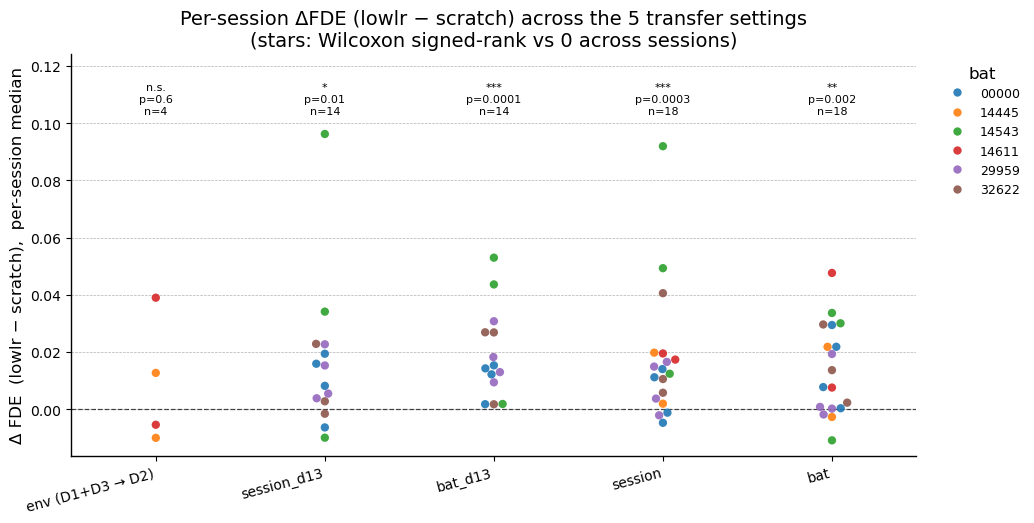

In [28]:
# ---- Load existing scratch + new lowlr per group ----
GROUPS_X = [
    ('env',          'env (D1+D3 → D2)'),
    ('session_d13',  'session_d13'),
    ('bat_d13',      'bat_d13'),
    ('session',      'session'),
    ('bat',          'bat'),
]
group_order = [g for g, _ in GROUPS_X]
group_label = dict(GROUPS_X)

scratch_frames, lowlr_frames = [], []
for g, _ in GROUPS_X:
    p_main  = os.path.join(OUT_ROOT, g, f'results_{g}.pkl')
    p_lowlr = os.path.join(OUT_ROOT, g, f'results_{g}_lowlr.pkl')
    if os.path.exists(p_main):
        d = pd.read_pickle(p_main)
        scratch_frames.append(d[d['mode'] == 'scratch'])
    if os.path.exists(p_lowlr):
        lowlr_frames.append(pd.read_pickle(p_lowlr))

if not scratch_frames or not lowlr_frames:
    print('Need both scratch and lowlr results on disk; rerun the sweep cells.')
else:
    df_s = pd.concat(scratch_frames, ignore_index=True)[
        ['group', 'target_session', 'neuron_idx', 'fde']]
    df_l = pd.concat(lowlr_frames, ignore_index=True)[
        ['group', 'target_session', 'neuron_idx', 'fde']]
    df_s = crop_for_plot(df_s, 'fde')
    df_l = crop_for_plot(df_l, 'fde')
    paired = df_s.merge(df_l, on=['group', 'target_session', 'neuron_idx'],
                         suffixes=('_scratch', '_lowlr'))
    paired['delta'] = paired['fde_lowlr'] - paired['fde_scratch']

    # per-session median ΔFDE
    sess_df = (paired.groupby(['group', 'target_session'])['delta']
                       .median().reset_index())
    sess_df['bat'] = sess_df['target_session'].map(bat_of)

    bats_ordered = sorted(sess_df['bat'].unique())
    palette = dict(zip(bats_ordered,
                       sns.color_palette('tab10', n_colors=len(bats_ordered))))


    def _wilcoxon_p_vs0(values, alternative='two-sided'):
        v = np.asarray(values, dtype=float)
        v = v[np.isfinite(v)]
        if len(v) < 1:
            return np.nan, len(v)
        try:
            return float(wilcoxon(v, alternative=alternative,
                                  zero_method='wilcox').pvalue), len(v)
        except ValueError:
            return np.nan, len(v)


    fig, ax = plt.subplots(figsize=(10.5, 5.4))
    sns.swarmplot(data=sess_df, x='group', y='delta', hue='bat',
                   order=group_order, hue_order=bats_ordered, palette=palette,
                   size=6, ax=ax, dodge=False, alpha=0.9)
    ax.axhline(0, color='k', lw=0.9, ls='--', alpha=0.7)

    # Wilcoxon vs 0 across sessions, per group
    stat_rows = []
    y_max = float(sess_df['delta'].max())
    y_min = float(sess_df['delta'].min())
    y_span = max(y_max - y_min, 1e-3)
    y_text = y_max + 0.06 * y_span
    for i, g in enumerate(group_order):
        vals = sess_df.loc[sess_df['group'] == g, 'delta'].values
        p, n = _wilcoxon_p_vs0(vals)
        med = float(np.median(vals)) if n else np.nan
        label = f'{p_to_stars(p)}\np={p:.1g}\nn={n}' if np.isfinite(p) else f'(n={n})'
        ax.text(i, y_text, label, ha='center', va='bottom', fontsize=8)
        stat_rows.append(dict(group=g, n_sessions=n, median_delta=med,
                               wilcoxon_p_two=p))
    ax.set_ylim(top=y_text + 0.20 * y_span)
    ax.set_xticklabels([group_label[g] for g in group_order], rotation=15, ha='right')
    ax.set_xlabel('')
    ax.set_ylabel('Δ FDE  (lowlr − scratch),  per-session median')
    ax.set_title('Per-session ΔFDE (lowlr − scratch) across the 5 transfer settings\n'
                 '(stars: Wilcoxon signed-rank vs 0 across sessions)')
    ax.legend(title='bat', bbox_to_anchor=(1.02, 1), loc='upper left',
              fontsize=9, frameon=False)
    plt.tight_layout()

    print('Per-group summary (Wilcoxon two-sided vs 0 on per-session ΔFDE):')
    display(pd.DataFrame(stat_rows).round(4))


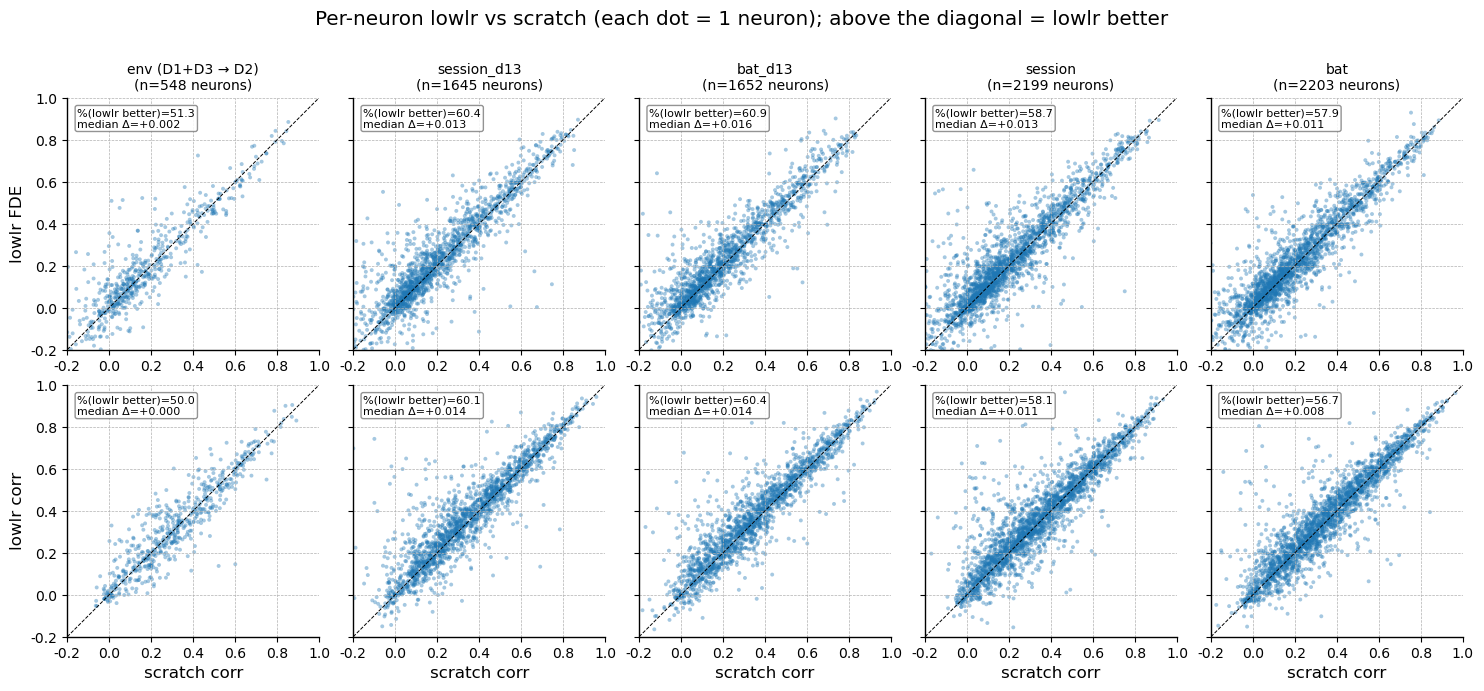

In [29]:
# Per-neuron scatter: lowlr vs scratch, one panel per experiment setting.
GROUPS_X = [
    ('env',          'env (D1+D3 → D2)'),
    ('session_d13',  'session_d13'),
    ('bat_d13',      'bat_d13'),
    ('session',      'session'),
    ('bat',          'bat'),
]
group_order = [g for g, _ in GROUPS_X]
group_label = dict(GROUPS_X)

scratch_frames, lowlr_frames = [], []
for g, _ in GROUPS_X:
    p_main  = os.path.join(OUT_ROOT, g, f'results_{g}.pkl')
    p_lowlr = os.path.join(OUT_ROOT, g, f'results_{g}_lowlr.pkl')
    if os.path.exists(p_main):
        d = pd.read_pickle(p_main)
        scratch_frames.append(d[d['mode'] == 'scratch'])
    if os.path.exists(p_lowlr):
        lowlr_frames.append(pd.read_pickle(p_lowlr))

if not scratch_frames or not lowlr_frames:
    print('Need both scratch and lowlr results on disk; rerun the sweep cells.')
else:
    df_s = pd.concat(scratch_frames, ignore_index=True)[
        ['group', 'target_session', 'neuron_idx', 'fde', 'corr']]
    df_l = pd.concat(lowlr_frames, ignore_index=True)[
        ['group', 'target_session', 'neuron_idx', 'fde', 'corr']]

    metric_specs = [
        ('fde',  'FDE',  (-0.2, 1.0)),
        ('corr', 'corr', (-0.2, 1.0)),
    ]
    fig, axes = plt.subplots(len(metric_specs), len(group_order),
                              figsize=(3.0 * len(group_order), 3.4 * len(metric_specs)),
                              sharex='row', sharey='row')
    for r, (metric, mlabel, (lo, hi)) in enumerate(metric_specs):
        s_m = crop_for_plot(df_s, metric)[
            ['group', 'target_session', 'neuron_idx', metric]
        ].rename(columns={metric: f'{metric}_scratch'})
        l_m = crop_for_plot(df_l, metric)[
            ['group', 'target_session', 'neuron_idx', metric]
        ].rename(columns={metric: f'{metric}_lowlr'})
        paired = s_m.merge(l_m, on=['group', 'target_session', 'neuron_idx'])
        for c, g in enumerate(group_order):
            ax = axes[r, c]
            sub = paired[paired['group'] == g]
            if sub.empty:
                ax.set_visible(False); continue
            x = sub[f'{metric}_scratch'].values
            y = sub[f'{metric}_lowlr'].values
            ax.scatter(x, y, s=8, alpha=0.4, edgecolors='none')
            ax.plot([lo, hi], [lo, hi], 'k--', lw=0.7)
            ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
            ax.set_aspect('equal')
            frac_better = float((y > x).mean())
            med_d = float(np.median(y - x))
            if r == 0:
                ax.set_title(f'{group_label[g]}\n(n={len(sub)} neurons)', fontsize=10)
            if r == len(metric_specs) - 1:
                ax.set_xlabel(f'scratch {mlabel}')
            if c == 0:
                ax.set_ylabel(f'lowlr {mlabel}')
            ax.text(0.04, 0.96,
                    f'%(lowlr better)={100*frac_better:.1f}\nmedian Δ={med_d:+.3f}',
                    transform=ax.transAxes, va='top', ha='left', fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white',
                              ec='gray', alpha=0.85))
    fig.suptitle('Per-neuron lowlr vs scratch (each dot = 1 neuron); above the diagonal = lowlr better',
                 y=1.005)
    plt.tight_layout()
